# SC4002 Group Assignment: Joint Intent Classification and Slot Filling (MASSIVE en-US)

**Group:** `G1`

The notebook runs top to bottom and has three parts:

- **Stage 1: baseline (Sections 0-13).** A joint BiLSTM on GloVe 6B word vectors, with a max-pooled intent head and a per-token softmax slot head. These sections also build the data pipeline, evaluation functions and training loop that Stage 2 reuses unchanged.
- **Stage 2: improved model (Sections 14-22).** Starts from an error analysis of the Stage 1 model, tests five changes one at a time on validation and keeps three: a character CNN, a CRF slot decoder with BIO constraints, and learning-rate decay.
- **Appendix.** Other experiments: alternative Stage 1 model families and Stage 2 variants that were not kept.

**Stage 1: baseline**

| Section | Content                                                 |
| ------- | ------------------------------------------------------- |
| 0       | Setup and configuration                                 |
| 1       | Load and verify the dataset                             |
| 2       | Text processing: slot parsing, tokenization, BIO labels |
| 3       | Shared evaluation functions and unit tests              |
| 4       | Pretrained word vectors (GloVe)                         |
| 5       | Preprocessing: tokenizer choice, vocabulary, label maps |
| 6       | Embedding matrix                                        |
| 7       | Stage 1 model definition and parameter count            |
| 8       | Training and evaluation utilities                       |
| 9       | Stage 1 hyperparameter sweep (validation only)          |
| 10      | Stage 1 official training run and checkpoint selection  |
| 11      | Stage 1 final evaluation from the saved checkpoint      |
| 12      | Stage 1 seed variance (validation only)                 |
| 13      | Stage 1 results table                                   |

**Stage 2: improved model**

| Section | Content                                                          |
| ------- | ---------------------------------------------------------------- |
| 14      | Stage 1 diagnosis (validation only)                              |
| 15      | From diagnosis to Stage 2 changes                                |
| 16      | Stage 2 model: one configurable joint model                      |
| 17      | Stage 2 development: greedy forward selection (validation only)  |
| 18      | Ablations (validation only)                                      |
| 19      | Stage 2 official training run and checkpoint selection           |
| 20      | Stage 2 final evaluation from the saved checkpoint               |
| 21      | Stage 2 diagnosis and comparison with Stage 1 (validation only)  |
| 22      | Final results table (Stage 1 and Stage 2)                        |

**Data hygiene.** All design and hyperparameter decisions use the training and validation splits only. The test split is evaluated once per stage, on the frozen checkpoint.


# Stage 1: Baseline

**Stage-1 system:** the joint BiLSTM of Section 7, trained and selected on validation (Sections 9-10) and tested once (Section 11).

Sections 0-6 and 8 are shared infrastructure (data, preprocessing, evaluation, word vectors, training loop). Stage 2 reuses them unchanged, so both stages are scored in exactly the same way.


## 0. Setup and configuration


In [1]:
%pip install -q seqeval==1.2.2

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import json
import platform
import random
import re
import shutil
import tarfile
import time
import urllib.request
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seqeval.metrics
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


print(f"python      {platform.python_version()}")
print(f"torch       {torch.__version__}")
print(f"numpy       {np.__version__}")
print(f"pandas      {pd.__version__}")
print(f"matplotlib  {matplotlib.__version__}")
print(f"device      {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

python      3.13.16
torch       2.11.0+cu130
numpy       2.1.3
pandas      2.3.3
matplotlib  3.10.0
device      cuda (Tesla T4)


In [ ]:
DATA_DIR = Path("data")
CKPT_DIR = Path("checkpoints")
FIG_DIR = Path("figures")
for d in (DATA_DIR, CKPT_DIR, FIG_DIR):
    d.mkdir(exist_ok=True)

MASSIVE_URL = "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz"
MASSIVE_TAR = DATA_DIR / "amazon-massive-dataset-1.0.tar.gz"
MASSIVE_JSONL = DATA_DIR / "en-US.jsonl"

GLOVE_URLS = [
    "https://nlp.stanford.edu/data/glove.6B.zip",
    "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip",
]
GLOVE_ZIP = DATA_DIR / "glove.6B.zip"
GLOVE_TXT = DATA_DIR / "glove.6B.300d.txt"
EMB_DIM = 300

EXPECTED_SPLITS = {"train": 11_514, "dev": 2_033, "test": 2_974}
PARAM_CAP = 20_000_000

STAGE1_DEFAULT = dict(
    hidden=256,          # BiLSTM hidden size per direction
    layers=2,            # BiLSTM layers
    dropout=0.5,         # embedding, between-layer and pre-head dropout
    word_dropout=0.1,    # prob. of replacing a training token with <unk>
    lr=1e-3,
    weight_decay=1e-2,   # AdamW, applied to weight matrices only (not embeddings or biases)
    batch_size=32,
    grad_clip=5.0,
)
MAX_EPOCHS = 50
PATIENCE = 8             # early stopping on the validation selection score
EVAL_BATCH_SIZE = 256

# One setting changed at a time from the default. Selection is on validation only.
STAGE1_SWEEP = [
    ("default", {}),
    ("lr=5e-4", {"lr": 5e-4}),
    ("lr=2e-3", {"lr": 2e-3}),
    ("dropout=0.3", {"dropout": 0.3}),
    ("word_dropout=0", {"word_dropout": 0.0}),
]
SWEEP_SEED = 42
OFFICIAL_SEED = 42       # fixed in advance
EXTRA_SEEDS = [43, 44]   # for mean +/- std on validation

## 1. Load and verify the dataset

We use the original MASSIVE 1.0 release, file `1.0/data/en-US.jsonl`, and split it by the existing `partition` field. No examples are added, removed or moved between splits.


In [4]:
def download(url, dest):
    """Download url to dest (via a .part file so an interrupted download is never mistaken for a complete one)."""
    dest = Path(dest)
    if dest.exists():
        print(f"found {dest}")
        return dest
    tmp = dest.with_name(dest.name + ".part")
    print(f"downloading {url}")
    t0 = time.time()
    with urllib.request.urlopen(url, timeout=60) as response, open(tmp, "wb") as f:
        shutil.copyfileobj(response, f, length=1 << 20)
    tmp.rename(dest)
    print(f"  saved {dest} ({dest.stat().st_size / 1e6:.1f} MB in {time.time() - t0:.0f}s)")
    return dest


if not MASSIVE_JSONL.exists():
    download(MASSIVE_URL, MASSIVE_TAR)
    with tarfile.open(MASSIVE_TAR, "r:gz") as tar:
        member = next(m for m in tar.getmembers() if m.name.endswith("1.0/data/en-US.jsonl"))
        with tar.extractfile(member) as src, open(MASSIVE_JSONL, "wb") as dst:
            shutil.copyfileobj(src, dst)
    print(f"extracted {member.name} -> {MASSIVE_JSONL}")

with open(MASSIVE_JSONL, encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

print("partitions in file:", dict(Counter(r["partition"] for r in records)))
splits = {name: [r for r in records if r["partition"] == name] for name in EXPECTED_SPLITS}
for name, expected in EXPECTED_SPLITS.items():
    print(f"{name:5s}: {len(splits[name]):,} examples")
    assert len(splits[name]) == expected, f"{name}: expected {expected}, got {len(splits[name])}"
assert sum(len(v) for v in splits.values()) == 16_521
assert all(r["locale"] == "en-US" for r in records)

prefix_mismatch = sum(not r["intent"].startswith(r["scenario"] + "_") for r in splits["train"])
print(f"train intents whose prefix is not their scenario: {prefix_mismatch}")
print("\nexample record:")
print({k: splits["train"][0][k] for k in ("id", "scenario", "intent", "utt", "annot_utt")})

downloading https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz
  saved data/amazon-massive-dataset-1.0.tar.gz (39.5 MB in 1s)
extracted 1.0/data/en-US.jsonl -> data/en-US.jsonl
partitions in file: {'test': 2974, 'train': 11514, 'dev': 2033}
train: 11,514 examples
dev  : 2,033 examples
test : 2,974 examples
train intents whose prefix is not their scenario: 0

example record:
{'id': '1', 'scenario': 'alarm', 'intent': 'alarm_set', 'utt': 'wake me up at nine am on friday', 'annot_utt': 'wake me up at [time : nine am] on [date : friday]'}


## 2. Text processing: slot parsing, tokenization, BIO labels

**Gold slots come directly from `annot_utt`.** Each `[type : span]` is parsed and aligned to `utt` character by character (ignoring whitespace), giving `(type, span text, char_start, char_end)`. The model only ever sees `utt`.

**Tokens keep their character offsets.** A token is labelled `B-type`/`I-type` if it overlaps a gold slot. When the model predicts a span over tokens `a..b`, its text is read back from `utt[start_a : end_b]`. This makes the slot metric independent of the tokenizer: gold pairs never change, whatever tokenizer a model uses.

**Decoding rule for invalid BIO sequences** (fixed for every experiment): a span starts at any `B-X` or at an `I-X` that does not continue an `X` span, and extends over the following `I-X` tags. This is the CoNLL convention, also used by `seqeval`.

Two tokenizers are defined; Section 5 picks one using the training split only.


In [5]:
SLOT_RE = re.compile(r"\[(\S+) : ([^\]]+)\]")


def norm_ws(s):
    return " ".join(s.split())


def parse_annot(utt, annot):
    """Gold slots as [(type, span_text, char_start, char_end)], with offsets into utt."""
    slots, i, pos = [], 0, 0

    def skip_space(i):
        while i < len(utt) and utt[i].isspace():
            i += 1
        return i

    def consume(segment, i):
        for ch in segment:
            if ch.isspace():
                continue
            i = skip_space(i)
            if i >= len(utt) or utt[i].lower() != ch.lower():
                raise ValueError(f"annot_utt does not match utt:\n  utt:   {utt!r}\n  annot: {annot!r}")
            i += 1
        return i

    for m in SLOT_RE.finditer(annot):
        i = consume(annot[pos:m.start()], i)
        start = skip_space(i)
        i = consume(m.group(2), start)
        slots.append((m.group(1), norm_ws(utt[start:i]), start, i))
        pos = m.end()
    i = consume(annot[pos:], i)
    if utt[i:].strip():
        raise ValueError(f"utt has extra text after alignment: {utt!r} / {annot!r}")
    return slots


TOKENIZERS = {
    # split on whitespace only
    "whitespace": re.compile(r"\S+"),
    # Penn-Treebank-style: split clitics ('s, n't, 're, ...) and punctuation, like GloVe 6B's own tokenization
    "ptb_split": re.compile(r"\w+(?=n't\b)|n't\b|'\w+|\w+|[^\w\s]"),
}


def tokenize(text, mode):
    """[(token, char_start, char_end)]"""
    return [(m.group(), m.start(), m.end()) for m in TOKENIZERS[mode].finditer(text)]


def bio_tags(tokens, slots):
    tags = ["O"] * len(tokens)
    for stype, _, s, e in slots:
        first = True
        for k, (_, ts, te) in enumerate(tokens):
            if ts < e and te > s and tags[k] == "O":
                tags[k] = ("B-" if first else "I-") + stype
                first = False
    return tags


def tags_to_spans(tags):
    """BIO tags -> [(type, first_token, last_token)] using the decoding rule above."""
    spans, k = [], 0
    while k < len(tags):
        if tags[k] == "O":
            k += 1
            continue
        stype, start = tags[k][2:], k
        k += 1
        while k < len(tags) and tags[k] == "I-" + stype:
            k += 1
        spans.append((stype, start, k - 1))
    return spans


def spans_to_pairs(spans, tokens, utt):
    """Token spans -> Counter of (type, span text), text read from utt via character offsets."""
    return Counter((stype, norm_ws(utt[tokens[a][1]:tokens[b][2]])) for stype, a, b in spans)


# quick illustration
_u = "wake me up at five am this week"
_slots = parse_annot(_u, "wake me up at [time : five am] [date : this week]")
_toks = tokenize(_u, "whitespace")
print(_slots)
print(list(zip([t[0] for t in _toks], bio_tags(_toks, _slots))))

[('time', 'five am', 14, 21), ('date', 'this week', 22, 31)]
[('wake', 'O'), ('me', 'O'), ('up', 'O'), ('at', 'O'), ('five', 'B-time'), ('am', 'I-time'), ('this', 'B-date'), ('week', 'I-date')]


## 3. Shared evaluation functions

Used, unchanged, for every experiment in both stages.

- **Intent accuracy** = 100 x correct intents / number of utterances.
- **Slot micro F1**: for each utterance, gold is the multiset of `(type, span text)` pairs from `annot_utt` and the prediction is the multiset decoded from the predicted tags. A true positive needs both type and span to match exactly. TP, FP and FN are pooled over all utterances, then F1 = 100 x 2TP / (2TP + FP + FN).
- **Exact match** (diagnostic only, not graded): intent correct and the slot multiset identical.
- **Selection score** for checkpoints and hyperparameters, the same in both stages: (intent accuracy + slot micro F1) / 2.


In [6]:
def intent_accuracy(gold, pred):
    assert len(gold) == len(pred) and len(gold) > 0
    return 100.0 * sum(g == p for g, p in zip(gold, pred)) / len(gold)


def slot_micro_prf(gold_pairs, pred_pairs):
    """gold_pairs, pred_pairs: lists (one per utterance) of Counter[(type, span_text)]."""
    assert len(gold_pairs) == len(pred_pairs)
    tp = fp = fn = 0
    for g, p in zip(gold_pairs, pred_pairs):
        hit = sum((g & p).values())
        tp += hit
        fp += sum(p.values()) - hit
        fn += sum(g.values()) - hit
    denom = 2 * tp + fp + fn
    return dict(
        f1=100.0 * 2 * tp / denom if denom else 100.0,
        precision=100.0 * tp / (tp + fp) if tp + fp else 0.0,
        recall=100.0 * tp / (tp + fn) if tp + fn else 0.0,
        tp=tp, fp=fp, fn=fn,
    )


def exact_match(gold_intents, pred_intents, gold_pairs, pred_pairs):
    hits = sum(gi == pi and gp == pp for gi, pi, gp, pp in zip(gold_intents, pred_intents, gold_pairs, pred_pairs))
    return 100.0 * hits / len(gold_intents)


def selection_score(intent_acc, slot_f1):
    return (intent_acc + slot_f1) / 2


def score_predictions(examples, pred_intents, pred_tags):
    """examples: preprocessed examples (Section 5). pred_tags: list of BIO tag lists aligned to each example's tokens."""
    gold_int = [ex["intent"] for ex in examples]
    gold_pairs = [ex["gold_pairs"] for ex in examples]
    pred_pairs = [spans_to_pairs(tags_to_spans(t), ex["tokens"], ex["utt"]) for ex, t in zip(examples, pred_tags)]
    acc = intent_accuracy(gold_int, pred_intents)
    prf = slot_micro_prf(gold_pairs, pred_pairs)
    return dict(
        intent_acc=acc,
        slot_f1=prf["f1"],
        slot_precision=prf["precision"],
        slot_recall=prf["recall"],
        exact_match=exact_match(gold_int, pred_intents, gold_pairs, pred_pairs),
        score=selection_score(acc, prf["f1"]),
    )

In [ ]:
# Unit tests for the evaluation functions
def _pred(utt, tags, mode="whitespace"):
    toks = tokenize(utt, mode)
    assert len(toks) == len(tags), (toks, tags)
    return spans_to_pairs(tags_to_spans(tags), toks, utt)


def _f1(gold, pred):
    return round(slot_micro_prf(gold, pred)["f1"], 4)


U = "wake me up at five am this week"
G = Counter({("time", "five am"): 1, ("date", "this week"): 1})

# 1. perfect prediction
assert _f1([G], [_pred(U, "O O O O B-time I-time B-date I-date".split())]) == 100.0
# 2. boundary error: 'five' instead of 'five am' -> TP=1, FP=1, FN=1
assert _f1([G], [_pred(U, "O O O O B-time O B-date I-date".split())]) == 50.0
# 3. right span, wrong type -> TP=1, FP=1, FN=1
assert _f1([G], [_pred(U, "O O O O B-date I-date B-date I-date".split())]) == 50.0
# 4. missed slot -> TP=1, FP=0, FN=1
assert _f1([G], [_pred(U, "O O O O B-time I-time O O".split())]) == round(100 * 2 / 3, 4)
# 5. spurious slot -> TP=2, FP=1, FN=0
assert _f1([G], [_pred(U, "B-person O O O B-time I-time B-date I-date".split())]) == 80.0
# 6. stray I- tags start a span (CoNLL rule)
assert _f1([G], [_pred(U, "O O O O I-time I-time I-date I-date".split())]) == 100.0
assert tags_to_spans(["B-time", "I-date", "I-date"]) == [("time", 0, 0), ("date", 1, 2)]
# 7. the same slot twice in one utterance is counted twice
U2 = "alarms at five and five"
G2 = Counter({("time", "five"): 2})
assert _f1([G2], [_pred(U2, "O O B-time O B-time".split())]) == 100.0
assert _f1([G2], [_pred(U2, "O O B-time O O".split())]) == round(100 * 2 / 3, 4)
# 8. no slots in gold or prediction
assert _f1([Counter()], [Counter()]) == 100.0
# 9. micro pooling over utterances (not an average of per-utterance F1)
assert _f1([G, Counter()], [_pred(U, "O O O O B-time I-time B-date I-date".split()), Counter({("date", "x"): 1})]) == 80.0
# 10. a slot glued to a clitic: whitespace tokens cannot represent it, ptb_split tokens can
U3 = "what is on today's schedule"
S3 = parse_annot(U3, "what is on [date : today]'s schedule")
assert S3 == [("date", "today", 11, 16)]
for mode, expected in [("whitespace", 0.0), ("ptb_split", 100.0)]:
    toks = tokenize(U3, mode)
    pred = spans_to_pairs(tags_to_spans(bio_tags(toks, S3)), toks, U3)
    assert _f1([Counter({("date", "today"): 1})], [pred]) == expected, mode
# 11. intent accuracy and exact match
assert intent_accuracy(["a", "b", "c", "d"], ["a", "b", "x", "d"]) == 75.0
assert exact_match(["a", "b"], ["a", "b"], [G, Counter()], [G, Counter({("date", "x"): 1})]) == 50.0
# 12. cross-check with seqeval on a case where both definitions apply
_gold_tags = [["O", "O", "O", "O", "B-time", "I-time", "B-date", "I-date"]]
_pred_tags = [["O", "O", "O", "O", "B-time", "O", "B-date", "I-date"]]
assert round(100 * seqeval.metrics.f1_score(_gold_tags, _pred_tags), 4) == _f1([G], [_pred(U, _pred_tags[0])])

print("all evaluation unit tests passed")

all evaluation unit tests passed


## 4. Pretrained word vectors (GloVe 6B, 300d)

Word vectors are the only pretrained component allowed. GloVe 6B is uncased, which matches the lowercased MASSIVE text. Only the rows for our training vocabulary are kept (Section 6), so the embedding table stays small.


In [8]:
if not GLOVE_TXT.exists():
    for url in GLOVE_URLS:
        try:
            download(url, GLOVE_ZIP)
            break
        except Exception as e:
            print(f"  failed: {e}")
    else:
        raise RuntimeError(f"Could not download GloVe. Put glove.6B.300d.txt at {GLOVE_TXT} manually.")
    with zipfile.ZipFile(GLOVE_ZIP) as z, z.open("glove.6B.300d.txt") as src, open(GLOVE_TXT, "wb") as dst:
        shutil.copyfileobj(src, dst, length=1 << 20)
    print(f"extracted {GLOVE_TXT}")

with open(GLOVE_TXT, encoding="utf-8") as f:
    GLOVE_WORDS = {line.split(" ", 1)[0] for line in f}
print(f"GloVe vocabulary: {len(GLOVE_WORDS):,} words")

downloading https://nlp.stanford.edu/data/glove.6B.zip
  failed: <urlopen error [Errno 113] No route to host>
downloading https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip
  saved data/glove.6B.zip (862.2 MB in 8s)
extracted data/glove.6B.300d.txt
GloVe vocabulary: 400,001 words


## 5. Preprocessing: tokenizer choice, vocabulary and label maps

**Tokenizer choice (training split only).** For each tokenizer we measure:

1. the _slot ceiling_: slot F1 obtained by decoding the gold BIO tags back to `(type, span)` pairs. Below 100 means some gold slot boundary falls inside a token and can never be predicted;
2. GloVe coverage of the training tokens.

We pick the tokenizer with the highest ceiling, breaking ties by coverage.

**Vocabulary** is built from training tokens only (lowercased), plus `<pad>` and `<unk>`. **Label maps** (intents, BIO tags) are built from the training split.


In [9]:
PAD, UNK, IGNORE = 0, 1, -100


def build_examples(split_records, mode):
    out = []
    for r in split_records:
        slots = parse_annot(r["utt"], r["annot_utt"])
        toks = tokenize(r["utt"], mode)
        assert len(toks) > 0, r
        out.append(dict(
            id=r["id"], utt=r["utt"], intent=r["intent"], scenario=r["scenario"],
            tokens=toks, words=[t[0].lower() for t in toks],
            tags=bio_tags(toks, slots),
            gold_pairs=Counter((s[0], s[1]) for s in slots),
        ))
    return out


def gold_ceiling(examples):
    decoded = [spans_to_pairs(tags_to_spans(ex["tags"]), ex["tokens"], ex["utt"]) for ex in examples]
    return slot_micro_prf([ex["gold_pairs"] for ex in examples], decoded)["f1"]


rows = []
for mode in TOKENIZERS:
    ex_train = build_examples(splits["train"], mode)
    counts = Counter(w for ex in ex_train for w in ex["words"])
    rows.append(dict(
        tokenizer=mode,
        train_slot_ceiling=gold_ceiling(ex_train),
        vocab_types=len(counts),
        glove_type_coverage=100 * sum(w in GLOVE_WORDS for w in counts) / len(counts),
        glove_token_coverage=100 * sum(c for w, c in counts.items() if w in GLOVE_WORDS) / sum(counts.values()),
    ))
tok_df = pd.DataFrame(rows)
display(tok_df.round(2))

best_row = max(rows, key=lambda r: (round(r["train_slot_ceiling"], 6), round(r["glove_token_coverage"], 6)))
TOKENIZER = best_row["tokenizer"]
print(f"chosen tokenizer: {TOKENIZER}")

,tokenizer,train_slot_ceiling,vocab_types,glove_type_coverage,glove_token_coverage
0,whitespace,100.0,5302,92.76,98.47
1,ptb_split,100.0,5143,96.42,99.65


chosen tokenizer: ptb_split


In [ ]:
EXAMPLES = {name: build_examples(recs, TOKENIZER) for name, recs in splits.items()}

# Pipeline checks (labels are only used to verify preprocessing, not to tune anything)
for name in ("train", "dev"):
    print(f"{name:5s} slot ceiling with {TOKENIZER}: {gold_ceiling(EXAMPLES[name]):.2f}")
missed = [ex for ex in EXAMPLES["train"]
          if spans_to_pairs(tags_to_spans(ex["tags"]), ex["tokens"], ex["utt"]) != ex["gold_pairs"]]
print(f"train utterances where gold tags cannot reproduce gold slots: {len(missed)}")
for ex in missed[:5]:
    print("  ", ex["utt"], "|", dict(ex["gold_pairs"]))

word_counts = Counter(w for ex in EXAMPLES["train"] for w in ex["words"])
ITOS = ["<pad>", "<unk>"] + [w for w, _ in word_counts.most_common()]
STOI = {w: i for i, w in enumerate(ITOS)}
V = len(ITOS)

ID2INTENT = sorted({ex["intent"] for ex in EXAMPLES["train"]})
INTENT2ID = {x: i for i, x in enumerate(ID2INTENT)}
SLOT_TYPES = sorted({t[2:] for ex in EXAMPLES["train"] for t in ex["tags"] if t != "O"})
ID2TAG = ["O"] + [f"{p}-{s}" for s in SLOT_TYPES for p in ("B", "I")]
TAG2ID = {t: i for i, t in enumerate(ID2TAG)}
N_INTENTS, N_TAGS = len(ID2INTENT), len(ID2TAG)

print(f"\nvocabulary size V = {V:,} (including <pad>, <unk>)")
print(f"intents = {N_INTENTS} (assignment: 60), slot types = {len(SLOT_TYPES)} (assignment: 55), BIO tags = {N_TAGS}")
if (N_INTENTS, len(SLOT_TYPES)) != (60, 55):
    print("note: label counts differ from the assignment description; labels unseen in training cannot be predicted")

lens = np.array([len(ex["tokens"]) for ex in EXAMPLES["train"]])
print(f"train tokens per utterance: mean {lens.mean():.1f}, max {lens.max()}")
dev_tokens = [w for ex in EXAMPLES["dev"] for w in ex["words"]]
print(f"dev tokens not in the training vocabulary: {100 * sum(w not in STOI for w in dev_tokens) / len(dev_tokens):.2f}%")


def encode(ex):
    return dict(
        ids=[STOI.get(w, UNK) for w in ex["words"]],
        tag_ids=[TAG2ID.get(t, IGNORE) for t in ex["tags"]],
        intent_id=INTENT2ID.get(ex["intent"], IGNORE),
    )


DATASETS = {name: [(i, encode(ex)) for i, ex in enumerate(exs)] for name, exs in EXAMPLES.items()}

ex0 = EXAMPLES["train"][0]
print("\nexample:", ex0["utt"], "->", ex0["intent"])
print(list(zip(ex0["words"], ex0["tags"])))

train slot ceiling with ptb_split: 100.00
dev   slot ceiling with ptb_split: 100.00
train utterances where gold tags cannot reproduce gold slots: 0

vocabulary size V = 5,145 (including <pad>, <unk>)
intents = 60 (assignment: 60), slot types = 55 (assignment: 55), BIO tags = 111
train tokens per utterance: mean 7.1, max 35
dev tokens not in the training vocabulary: 3.13%

example: wake me up at nine am on friday -> alarm_set
[('wake', 'O'), ('me', 'O'), ('up', 'O'), ('at', 'O'), ('nine', 'B-time'), ('am', 'I-time'), ('on', 'O'), ('friday', 'B-date')]


## 6. Embedding matrix

Rows for training words found in GloVe are initialised with their GloVe vectors. `<unk>` and training words missing from GloVe get small random vectors (same scale as GloVe); `<pad>` is all zeros. The matrix is fine-tuned during training, so `<unk>` (trained through word dropout) and the random rows can learn. Words outside the training vocabulary map to `<unk>` at test time; no external lookup is used at inference.


In [11]:
glove_vecs = {}
with open(GLOVE_TXT, encoding="utf-8") as f:
    for line in f:
        word, rest = line.rstrip("\n").split(" ", 1)
        if word in STOI:
            glove_vecs[word] = np.asarray(rest.split(" "), dtype=np.float32)

found = np.stack(list(glove_vecs.values()))
assert found.shape[1] == EMB_DIM
rng = np.random.default_rng(0)
EMB_MATRIX = rng.normal(0.0, found.std(), size=(V, EMB_DIM)).astype(np.float32)
for w, vec in glove_vecs.items():
    EMB_MATRIX[STOI[w]] = vec
EMB_MATRIX[PAD] = 0.0

n_types = V - 2
n_tok = sum(word_counts.values())
print(f"training word types found in GloVe: {len(glove_vecs):,} / {n_types:,} ({100 * len(glove_vecs) / n_types:.2f}%)")
print(f"training tokens covered by GloVe:  {100 * sum(c for w, c in word_counts.items() if w in glove_vecs) / n_tok:.2f}%")
print(f"embedding matrix: {EMB_MATRIX.shape}")

training word types found in GloVe: 4,960 / 5,143 (96.44%)
training tokens covered by GloVe:  99.65%
embedding matrix: (5145, 300)


## 7. Stage 1 model: joint BiLSTM

One shared encoder, two heads, one loss. A single forward pass produces both outputs.

| Part         | Details                                                                                                                |
| ------------ | ---------------------------------------------------------------------------------------------------------------------- |
| Input        | token ids of `utt` (tokenizer from Section 5), lowercased; unknown words map to `<unk>`                                |
| Embedding    | V x 300, initialised from GloVe 6B, fine-tuned; dropout                                                                |
| Word dropout | during training only, each real token is replaced by `<unk>` with probability `word_dropout`                           |
| Encoder      | 2-layer bidirectional LSTM, 256 units per direction, dropout between layers, packed sequences so padding is never read |
| Intent head  | max-pool over the real (non-padding) time steps -> dropout -> Linear(512, #intents)                                    |
| Slot head    | per token: dropout -> Linear(512, #BIO tags), softmax                                                                  |
| Outputs      | one intent label; one BIO tag per token, decoded to `[type : span]` pairs with the rule in Section 2                   |
| Loss         | CE(intent) + CE(slot tags), padding positions ignored                                                                  |
| Optimizer    | AdamW, lr 1e-3 (tuned in Section 9), weight decay 0.01 on weight matrices, gradient-norm clipping 5, batch size 32     |
| Selection    | best validation (intent accuracy + slot micro F1) / 2, early stopping with patience 8, at most 50 epochs               |


In [12]:
class JointBiLSTM(nn.Module):
    """Stage 1: shared BiLSTM encoder, max-pooled intent head, per-token softmax slot head."""

    def __init__(self, emb_matrix, n_intents, n_tags, hidden=256, layers=2, dropout=0.5,
                 word_dropout=0.1, **_unused):
        super().__init__()
        self.word_dropout = word_dropout
        # torch.tensor copies, so training never modifies the shared EMB_MATRIX used by later runs
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=PAD)
        self.emb_dropout = nn.Dropout(dropout)
        self.encoder = nn.LSTM(emb_matrix.shape[1], hidden, num_layers=layers, bidirectional=True,
                               batch_first=True, dropout=dropout if layers > 1 else 0.0)
        self.head_dropout = nn.Dropout(dropout)
        self.intent_head = nn.Linear(2 * hidden, n_intents)
        self.slot_head = nn.Linear(2 * hidden, n_tags)
        self.ce = nn.CrossEntropyLoss(ignore_index=IGNORE)

    def forward(self, batch):
        ids, lengths, mask = batch["ids"], batch["lengths"], batch["mask"]
        if self.training and self.word_dropout > 0:
            drop = (torch.rand(ids.shape, device=ids.device) < self.word_dropout) & mask
            ids = ids.masked_fill(drop, UNK)
        x = self.emb_dropout(self.embedding(ids))
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.encoder(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=ids.size(1))
        pooled = h.masked_fill(~mask.unsqueeze(-1), float("-inf")).max(dim=1).values
        return {
            "intent": self.intent_head(self.head_dropout(pooled)),
            "slot": self.slot_head(self.head_dropout(h)),
        }

    def loss(self, out, batch):
        intent_loss = self.ce(out["intent"], batch["intents"])
        slot_loss = self.ce(out["slot"].reshape(-1, out["slot"].size(-1)), batch["tags"].reshape(-1))
        return {"total": intent_loss + slot_loss, "intent": intent_loss, "slot": slot_loss}

    def decode(self, out, batch):
        intents = out["intent"].argmax(-1).tolist()
        tags = out["slot"].argmax(-1).tolist()
        return intents, [t[:n] for t, n in zip(tags, batch["lengths"].tolist())]


def build_stage1(cfg):
    return JointBiLSTM(EMB_MATRIX, N_INTENTS, N_TAGS, **cfg)


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


def param_breakdown(model):
    rows = [(name, sum(p.numel() for p in m.parameters())) for name, m in model.named_children()]
    rows = [(n, c) for n, c in rows if c > 0]
    total, trainable = count_params(model)
    df = pd.DataFrame(rows + [("TOTAL", total), ("trainable", trainable)], columns=["component", "parameters"])
    df["parameters"] = df["parameters"].map("{:,}".format)
    return df, total, trainable


_m = build_stage1(STAGE1_DEFAULT)
_df, _total, _trainable = param_breakdown(_m)
display(_df)
print(f"total parameters in the Stage 1 pipeline: {_total:,} (cap {PARAM_CAP:,})")
assert _total <= PARAM_CAP
del _m

,component,parameters
0,embedding,"1,543,500"
1,encoder,"2,719,744"
2,intent_head,"30,780"
3,slot_head,"56,943"
4,TOTAL,"4,350,967"
5,trainable,"4,350,967"


total parameters in the Stage 1 pipeline: 4,350,967 (cap 20,000,000)


## 8. Training and evaluation utilities

Shared by both stages. A model only has to implement `forward(batch)`, `loss(out, batch)` and `decode(out, batch)`, so Stage 2 models (for example with a CRF decoder) plug into the same loop and the same evaluation.


In [ ]:
def collate(batch):
    idx = [b[0] for b in batch]
    items = [b[1] for b in batch]
    lengths = torch.tensor([len(x["ids"]) for x in items])
    T = int(lengths.max())
    ids = torch.full((len(items), T), PAD, dtype=torch.long)
    tags = torch.full((len(items), T), IGNORE, dtype=torch.long)
    for i, x in enumerate(items):
        n = len(x["ids"])
        ids[i, :n] = torch.tensor(x["ids"])
        tags[i, :n] = torch.tensor(x["tag_ids"])
    return dict(
        idx=torch.tensor(idx), ids=ids, lengths=lengths,
        mask=torch.arange(T)[None, :] < lengths[:, None],
        tags=tags, intents=torch.tensor([x["intent_id"] for x in items]),
    )


def make_loader(split, batch_size, shuffle, seed=None):
    gen = None
    if shuffle:
        gen = torch.Generator()
        gen.manual_seed(seed)
    return DataLoader(DATASETS[split], batch_size=batch_size, shuffle=shuffle, collate_fn=collate, generator=gen)


def to_device(batch):
    return {k: v.to(DEVICE) for k, v in batch.items()}


@torch.no_grad()
def evaluate(model, split):
    """Returns (metrics dict incl. mean loss, predicted intents, predicted tag lists) in example order."""
    model.eval()
    n = len(EXAMPLES[split])
    pred_int, pred_tags = [None] * n, [None] * n
    loss_sum, count = 0.0, 0
    for batch in make_loader(split, EVAL_BATCH_SIZE, shuffle=False):
        b = to_device(batch)
        out = model(b)
        loss_sum += model.loss(out, b)["total"].item() * len(batch["idx"])
        count += len(batch["idx"])
        ints, tag_seqs = model.decode(out, b)
        for i, it, ts in zip(batch["idx"].tolist(), ints, tag_seqs):
            pred_int[i] = ID2INTENT[it]
            pred_tags[i] = [ID2TAG[t] for t in ts]
    metrics = score_predictions(EXAMPLES[split], pred_int, pred_tags)
    metrics["loss"] = loss_sum / count
    return metrics, pred_int, pred_tags


def make_optimizer(model, cfg):
    """AdamW. Weight decay only on weight matrices: never on embedding tables, biases or CRF scores."""
    emb_params = {id(p) for m in model.modules() if isinstance(m, nn.Embedding) for p in m.parameters()}
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (decay if p.ndim >= 2 and id(p) not in emb_params and not name.startswith("crf") else no_decay).append(p)
    return torch.optim.AdamW([
        {"params": decay, "weight_decay": cfg["weight_decay"]},
        {"params": no_decay, "weight_decay": 0.0},
    ], lr=cfg["lr"])


def train_one_epoch(model, loader, opt, grad_clip):
    model.train()
    sums, n = Counter(), 0
    for batch in loader:
        b = to_device(batch)
        losses = model.loss(model(b), b)
        opt.zero_grad(set_to_none=True)
        losses["total"].backward()
        nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        opt.step()
        bs = len(batch["idx"])
        for k, v in losses.items():
            sums[k] += v.item() * bs
        n += bs
    return {k: v / n for k, v in sums.items()}


def save_checkpoint(path, model, cfg, seed, row, stage):
    torch.save(dict(
        stage=stage, model_class=type(model).__name__, model_state=model.state_dict(),
        cfg=cfg, seed=seed, epoch=row["epoch"], dev_metrics=dict(row),
        vocab=ITOS, intents=ID2INTENT, tags=ID2TAG, tokenizer=TOKENIZER,
    ), path)


def load_checkpoint(path, build_fn):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    assert ck["vocab"] == ITOS and ck["intents"] == ID2INTENT and ck["tags"] == ID2TAG and ck["tokenizer"] == TOKENIZER
    model = build_fn(ck["cfg"]).to(DEVICE)
    model.load_state_dict(ck["model_state"])
    model.eval()
    return model, ck


def run_training(build_fn, cfg, seed, ckpt_path=None, verbose=True, stage="stage1"):
    """Train on the training split; select the epoch with the best validation selection score."""
    set_seed(seed)
    model = build_fn(cfg).to(DEVICE)
    opt = make_optimizer(model, cfg)
    sched = (torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)
             if cfg.get("lr_schedule", "none") == "plateau" else None)
    loader = make_loader("train", cfg["batch_size"], shuffle=True, seed=seed)
    history, best, bad, t_start = [], None, 0, time.time()
    if verbose:
        print(f"{'epoch':>5} | {'train loss':>10} | {'dev loss':>8} | {'dev intent':>10} | {'dev slot F1':>11} | {'dev score':>9} | {'time':>6}")
    for epoch in range(1, MAX_EPOCHS + 1):
        t0 = time.time()
        tr = train_one_epoch(model, loader, opt, cfg["grad_clip"])
        dev, _, _ = evaluate(model, "dev")
        row = dict(
            epoch=epoch,
            train_loss=tr["total"], train_intent_loss=tr["intent"], train_slot_loss=tr["slot"],
            dev_loss=dev["loss"], dev_intent_acc=dev["intent_acc"], dev_slot_f1=dev["slot_f1"],
            dev_exact_match=dev["exact_match"], dev_score=dev["score"],
            epoch_seconds=time.time() - t0, elapsed_seconds=time.time() - t_start,
            lr=opt.param_groups[0]["lr"],
        )
        history.append(row)
        if sched is not None:
            sched.step(row["dev_score"])
        improved = best is None or row["dev_score"] > best["dev_score"]
        if improved:
            best, bad = dict(row), 0
            if ckpt_path is not None:
                save_checkpoint(ckpt_path, model, cfg, seed, row, stage)
        else:
            bad += 1
        if verbose:
            print(f"{epoch:>5} | {row['train_loss']:>10.4f} | {row['dev_loss']:>8.4f} | {row['dev_intent_acc']:>10.2f} | "
                  f"{row['dev_slot_f1']:>11.2f} | {row['dev_score']:>9.2f} | {row['epoch_seconds']:>5.1f}s {'*' if improved else ''}")
        if bad >= PATIENCE:
            if verbose:
                print(f"early stopping: no improvement for {PATIENCE} epochs")
            break
    return model, history, best


def plot_curves(history, best_epoch, title, path):
    h = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h["epoch"], h["train_loss"], label="train loss")
    axes[0].plot(h["epoch"], h["dev_loss"], label="validation loss")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss (intent CE + slot CE)"); axes[0].legend()
    axes[1].plot(h["epoch"], h["dev_intent_acc"], label="validation intent accuracy")
    axes[1].plot(h["epoch"], h["dev_slot_f1"], label="validation slot micro F1")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("%"); axes[1].legend()
    for ax in axes:
        ax.axvline(best_epoch, color="grey", linestyle="--", linewidth=1)
        ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
        ax.grid(alpha=0.3)
    fig.suptitle(f"{title} (dashed line: selected epoch {best_epoch})")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()

## 9. Stage 1 hyperparameter sweep (validation only)

A small sweep so that the baseline is properly tuned: one setting is changed at a time from the default, one seed each. The configuration with the best validation selection score is used for the official run. No test data is touched here.


In [14]:
sweep_rows = []
for name, override in STAGE1_SWEEP:
    cfg = {**STAGE1_DEFAULT, **override}
    t0 = time.time()
    m, hist, best = run_training(build_stage1, cfg, seed=SWEEP_SEED, verbose=False)
    del m
    sweep_rows.append(dict(
        run=name, best_epoch=best["epoch"], epochs_run=len(hist),
        dev_intent_acc=best["dev_intent_acc"], dev_slot_f1=best["dev_slot_f1"], dev_score=best["dev_score"],
        minutes=(time.time() - t0) / 60,
    ))
    print(f"{name:16s} best epoch {best['epoch']:>2}/{len(hist):>2} | intent {best['dev_intent_acc']:.2f} | "
          f"slot F1 {best['dev_slot_f1']:.2f} | score {best['dev_score']:.2f} | {(time.time() - t0) / 60:.1f} min")

sweep_df = pd.DataFrame(sweep_rows)
display(sweep_df.round(2))
sweep_df.to_csv("stage1_sweep.csv", index=False)

best_run = sweep_df.loc[sweep_df["dev_score"].idxmax(), "run"]
STAGE1_CFG = {**STAGE1_DEFAULT, **dict(STAGE1_SWEEP)[best_run]}
print(f"selected configuration: {best_run}")
print(STAGE1_CFG)

default          best epoch 29/37 | intent 87.51 | slot F1 76.17 | score 81.84 | 2.9 min
lr=5e-4          best epoch 36/44 | intent 87.36 | slot F1 76.98 | score 82.17 | 3.2 min
lr=2e-3          best epoch 24/32 | intent 86.77 | slot F1 76.58 | score 81.68 | 2.3 min
dropout=0.3      best epoch 23/31 | intent 87.01 | slot F1 77.55 | score 82.28 | 2.3 min
word_dropout=0   best epoch 38/46 | intent 86.23 | slot F1 75.42 | score 80.82 | 3.3 min


,run,best_epoch,epochs_run,dev_intent_acc,dev_slot_f1,dev_score,minutes
0,default,29,37,87.51,76.17,81.84,2.91
1,lr=5e-4,36,44,87.36,76.98,82.17,3.22
2,lr=2e-3,24,32,86.77,76.58,81.68,2.33
3,dropout=0.3,23,31,87.01,77.55,82.28,2.26
4,word_dropout=0,38,46,86.23,75.42,80.82,3.33


selected configuration: dropout=0.3
{'hidden': 256, 'layers': 2, 'dropout': 0.3, 'word_dropout': 0.1, 'lr': 0.001, 'weight_decay': 0.01, 'batch_size': 32, 'grad_clip': 5.0}


## 10. Stage 1 official training run and checkpoint selection

Selected configuration, seed fixed in advance. Every epoch logs training and validation losses, validation metrics and elapsed time. The checkpoint with the highest validation selection score is saved (`*` marks an improvement).


In [15]:
STAGE1_CKPT = CKPT_DIR / "stage1_best.pt"
stage1_train_model, stage1_history, stage1_best = run_training(
    build_stage1, STAGE1_CFG, seed=OFFICIAL_SEED, ckpt_path=STAGE1_CKPT, verbose=True, stage="stage1")
del stage1_train_model
pd.DataFrame(stage1_history).to_csv("stage1_history.csv", index=False)

print(f"\nselected checkpoint: epoch {stage1_best['epoch']} (of {len(stage1_history)} run)")
print(f"validation selection score: {stage1_best['dev_score']:.2f} "
      f"(intent accuracy {stage1_best['dev_intent_acc']:.2f}, slot micro F1 {stage1_best['dev_slot_f1']:.2f})")
print(f"checkpoint file: {STAGE1_CKPT}")
print(f"total training time: {stage1_history[-1]['elapsed_seconds'] / 60:.1f} min")

epoch | train loss | dev loss | dev intent | dev slot F1 | dev score |   time
    1 |     3.7279 |   1.7646 |      69.26 |       36.46 |     52.86 |   4.4s *
    2 |     1.6727 |   1.1833 |      80.57 |       56.44 |     68.50 |   4.5s *
    3 |     1.2381 |   0.9630 |      83.37 |       64.40 |     73.89 |   4.4s *
    4 |     1.0017 |   0.9285 |      84.80 |       68.14 |     76.47 |   4.5s *
    5 |     0.8610 |   0.8904 |      85.00 |       69.76 |     77.38 |   4.4s *
    6 |     0.7427 |   0.8615 |      85.74 |       70.46 |     78.10 |   4.4s *
    7 |     0.6823 |   0.8552 |      85.49 |       72.28 |     78.89 |   4.4s *
    8 |     0.6118 |   0.8630 |      85.64 |       73.41 |     79.53 |   4.3s *
    9 |     0.5650 |   0.8639 |      85.78 |       72.58 |     79.18 |   4.5s 
   10 |     0.5223 |   0.8774 |      86.42 |       73.28 |     79.85 |   4.4s *
   11 |     0.4905 |   0.8842 |      86.28 |       72.95 |     79.62 |   4.4s 
   12 |     0.4517 |   0.8937 |      86.92 |

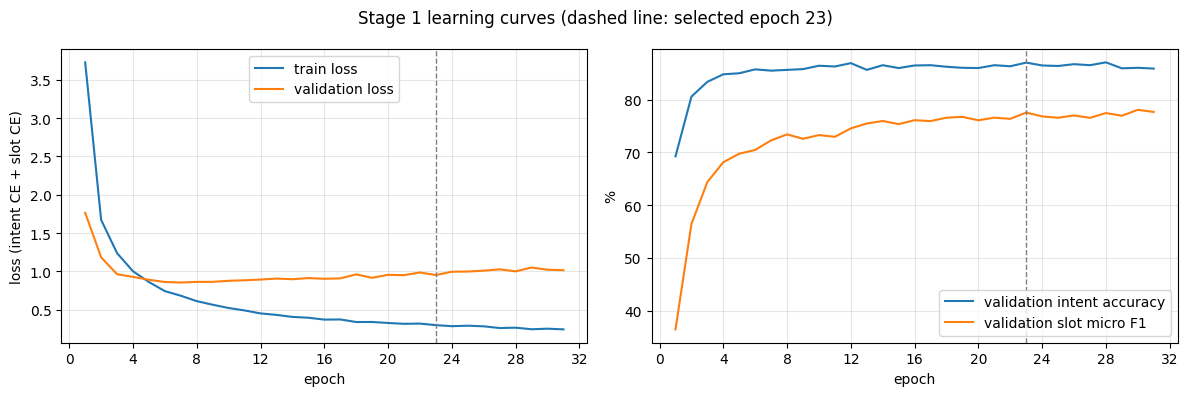

In [16]:
plot_curves(stage1_history, stage1_best["epoch"], "Stage 1 learning curves", FIG_DIR / "stage1_curves.png")

## 11. Stage 1 final evaluation from the saved checkpoint

A fresh model is built and the saved checkpoint is loaded from disk. Without further training, it is evaluated on the validation and test splits. The validation score must equal the best score logged during training.


In [ ]:
stage1_model, stage1_ck = load_checkpoint(STAGE1_CKPT, build_stage1)
stage1_dev, stage1_dev_int, stage1_dev_tags = evaluate(stage1_model, "dev")
stage1_test, _, _ = evaluate(stage1_model, "test")

print(f"checkpoint: {STAGE1_CKPT} (epoch {stage1_ck['epoch']})")
print(f"validation score logged during training: {stage1_ck['dev_metrics']['dev_score']:.6f}")
print(f"validation score after reloading:       {stage1_dev['score']:.6f}")
assert abs(stage1_dev["score"] - stage1_ck["dev_metrics"]["dev_score"]) < 1e-6

# Cross-check of our slot F1 against seqeval on token-level BIO tags (validation)
_seqeval_f1 = 100 * seqeval.metrics.f1_score([ex["tags"] for ex in EXAMPLES["dev"]], stage1_dev_tags)
print(f"validation slot F1: ours {stage1_dev['slot_f1']:.2f}, seqeval {_seqeval_f1:.2f}")

stage1_eval_df = pd.DataFrame([
    {"split": "validation", **{k: stage1_dev[k] for k in ("intent_acc", "slot_f1", "slot_precision", "slot_recall", "exact_match")}},
    {"split": "test", **{k: stage1_test[k] for k in ("intent_acc", "slot_f1", "slot_precision", "slot_recall", "exact_match")}},
])
display(stage1_eval_df.round(2))
print(f"\nStage 1 TEST: intent accuracy {stage1_test['intent_acc']:.2f}%, slot micro F1 {stage1_test['slot_f1']:.2f}%")

checkpoint: checkpoints/stage1_best.pt (epoch 23)
validation score logged during training: 82.279660
validation score after reloading:       82.279660
validation slot F1: ours 77.55, seqeval 77.55


,split,intent_acc,slot_f1,slot_precision,slot_recall,exact_match
0,validation,87.01,77.55,76.03,79.13,66.21
1,test,85.84,75.12,74.48,75.77,65.16



Stage 1 TEST: intent accuracy 85.84%, slot micro F1 75.12%


## 12. Stage 1 seed variance (validation only)

The same configuration trained with two more seeds, to show how much of a validation difference is just noise. Only validation scores are reported; these runs are not used for the official checkpoint.


In [18]:
seed_rows = [dict(seed=OFFICIAL_SEED, best_epoch=stage1_best["epoch"], dev_intent_acc=stage1_best["dev_intent_acc"],
                  dev_slot_f1=stage1_best["dev_slot_f1"], dev_score=stage1_best["dev_score"])]
for s in EXTRA_SEEDS:
    m, hist, best = run_training(build_stage1, STAGE1_CFG, seed=s, verbose=False)
    del m
    seed_rows.append(dict(seed=s, best_epoch=best["epoch"], dev_intent_acc=best["dev_intent_acc"],
                          dev_slot_f1=best["dev_slot_f1"], dev_score=best["dev_score"]))
stage1_seeds_df = pd.DataFrame(seed_rows)
display(stage1_seeds_df.round(2))
for col in ("dev_intent_acc", "dev_slot_f1", "dev_score"):
    print(f"{col:15s} mean {stage1_seeds_df[col].mean():.2f} +/- {stage1_seeds_df[col].std(ddof=1):.2f} (std over {len(stage1_seeds_df)} seeds)")

,seed,best_epoch,dev_intent_acc,dev_slot_f1,dev_score
0,42,23,87.01,77.55,82.28
1,43,20,86.87,76.93,81.90
2,44,27,85.93,77.94,81.93


dev_intent_acc  mean 86.60 +/- 0.59 (std over 3 seeds)
dev_slot_f1     mean 77.47 +/- 0.51 (std over 3 seeds)
dev_score       mean 82.04 +/- 0.21 (std over 3 seeds)


## 13. Stage 1 results table

Generated from the variables above (no numbers are typed by hand). "Number of epochs" is the epoch of the selected checkpoint; the number of epochs actually run before early stopping is printed below the table. Stage 2 rows will be appended in the Stage 2 section.


In [19]:
def results_rows(name, model, dev, test, best_epoch):
    total, trainable = count_params(model)
    return [
        {"Model version": name, "Split": "Validation", "Total # parameters": f"{total:,}",
         "Total # trainable parameters": f"{trainable:,}", "Intent accuracy (%)": f"{dev['intent_acc']:.2f}",
         "Slot micro-F1 (%)": f"{dev['slot_f1']:.2f}", "Number of epochs": str(best_epoch)},
        {"Model version": name, "Split": "Test", "Total # parameters": "Same as above",
         "Total # trainable parameters": "Same as above", "Intent accuracy (%)": f"{test['intent_acc']:.2f}",
         "Slot micro-F1 (%)": f"{test['slot_f1']:.2f}", "Number of epochs": "Same as above"},
    ]


RESULTS = results_rows("Stage-1 system", stage1_model, stage1_dev, stage1_test, stage1_ck["epoch"])
display(pd.DataFrame(RESULTS))
print(f"Stage 1: selected epoch {stage1_ck['epoch']}, {len(stage1_history)} epochs run (early stopping, patience {PATIENCE})")

with open("results_stage1.json", "w") as f:
    json.dump(dict(rows=RESULTS, dev=stage1_dev, test=stage1_test, cfg=STAGE1_CFG,
                   epochs_run=len(stage1_history), selected_epoch=stage1_ck["epoch"]), f, indent=2)

,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,Stage-1 system,Validation,"4,350,967","4,350,967",87.01,77.55,23
1,Stage-1 system,Test,Same as above,Same as above,85.84,75.12,Same as above


Stage 1: selected epoch 23, 31 epochs run (early stopping, patience 8)


# Stage 2: Improved model

**Stage-2 system:** the Stage 1 joint BiLSTM plus a character CNN on each word, a CRF slot decoder with BIO constraints, and learning-rate decay on plateau. Section 16 describes every option.

How Stage 2 was built:

1. **Diagnose** where the Stage 1 model fails, on validation (Section 14).
2. **Propose** one change for each weakness found (Section 15).
3. **Select** changes one at a time over 3 seeds, keeping a change only if it beats the noise margin (Section 17), then remove each kept change again to check it still helps (Section 18).
4. **Train and test** the selected configuration once (Sections 19-20), compare its errors with Stage 1 (Section 21) and report both stages side by side (Section 22).


## 14. Stage 1 diagnosis (validation split only)

Before changing the model, we measure where Stage 1 fails. Every analysis below uses the **validation** predictions of the selected Stage 1 checkpoint (Section 11); the test split is not looked at. The same functions are run again on Stage 2 at the end, for a before/after comparison.

| Analysis                                                                                        | What a bad result would point to                                                                       |
| ----------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------ |
| Predicted vs gold slot counts, precision vs recall                                              | Over-prediction (many spurious or fragmented spans)                                                    |
| Slot errors by kind: wrong type, boundary, boundary + type, missed, spurious                    | Boundary and fragment errors: model tag transitions (CRF). Wrong type: let the intent inform the slots |
| Invalid BIO tags (an `I-X` that does not continue an `X` span) and gold spans split into pieces | The tagger ignores tag order: CRF                                                                      |
| Scores on utterances and spans with out-of-vocabulary words, vs the rest                        | Unknown words: character-level word features                                                           |
| Predicted slot types never seen with the predicted intent in training                           | Slots inconsistent with the intent: intent-to-slot conditioning                                        |
| Intent errors inside vs across scenarios; most confused pairs                                   | Fine-grained intent confusions: better sentence representation                                         |
| Slot F1 when the intent is right vs wrong                                                       | How tightly the two tasks are coupled                                                                  |
| Per-slot-type F1 vs training frequency                                                          | Rare slot types                                                                                        |
| A fixed random sample of errors, read by hand                                                   | Annotation ambiguity and what the numbers miss                                                         |


In [ ]:
from collections import defaultdict

pd.set_option("display.max_colwidth", None)  # show full measure names in the diagnosis tables
ERROR_KINDS =["wrong type", "boundary", "boundary + type", "missed", "spurious"]

TRAIN_INTENT_SLOTS = defaultdict(set)
TRAIN_SLOT_FREQ = Counter()
for _ex in EXAMPLES["train"]:
    for _stype, _, _ in tags_to_spans(_ex["tags"]):
        TRAIN_INTENT_SLOTS[_ex["intent"]].add(_stype)
        TRAIN_SLOT_FREQ[_stype] += 1


def _overlap(a, b):
    return a[1] <= b[2] and b[1] <= a[2]


def _pct(a, b):
    return 100.0 * a / b if b else float("nan")


def slot_error_breakdown(examples, pred_tags):
    """Each gold span is correct, wrong type (same words), boundary (same type, overlapping words),
    boundary + type, or missed (no overlapping prediction). Each predicted span overlapping no gold span is spurious."""
    c = Counter()
    for ex, pt in zip(examples, pred_tags):
        gold, pred = tags_to_spans(ex["tags"]), tags_to_spans(pt)
        pred_set, gold_set = set(pred), set(gold)
        for g in gold:
            if g in pred_set:
                c["correct"] += 1
                continue
            over = [p for p in pred if _overlap(p, g)]
            if any(p[1:] == g[1:] for p in over):
                c["wrong type"] += 1
            elif any(p[0] == g[0] for p in over):
                c["boundary"] += 1
            elif over:
                c["boundary + type"] += 1
            else:
                c["missed"] += 1
            if len(over) >= 2:
                c["split into pieces"] += 1
        for p in pred:
            if p not in gold_set and not any(_overlap(p, g) for g in gold):
                c["spurious"] += 1
    return c


def invalid_bio(tag_lists):
    """Number of I-X tags that do not continue an X span, and number of utterances containing one."""
    bad_tags = bad_utts = 0
    for tags in tag_lists:
        prev, bad = "O", 0
        for t in tags:
            if t.startswith("I-") and prev[2:] != t[2:]:
                bad += 1
            prev = t
        bad_tags += bad
        bad_utts += bad > 0
    return bad_tags, bad_utts


def subset_scores(examples, pred_int, pred_tags, mask):
    idx = [i for i, keep in enumerate(mask) if keep]
    if not idx:
        return dict(n=0, intent_acc=float("nan"), slot_f1=float("nan"))
    m = score_predictions([examples[i] for i in idx], [pred_int[i] for i in idx], [pred_tags[i] for i in idx])
    return dict(n=len(idx), intent_acc=m["intent_acc"], slot_f1=m["slot_f1"])


def span_recall_by_oov(examples, pred_tags):
    """Share of gold spans predicted exactly, for spans with / without a word outside the training vocabulary."""
    hit, tot = Counter(), Counter()
    for ex, pt in zip(examples, pred_tags):
        pred = set(tags_to_spans(pt))
        for g in tags_to_spans(ex["tags"]):
            key = "oov" if any(ex["words"][k] not in STOI for k in range(g[1], g[2] + 1)) else "in_vocab"
            tot[key] += 1
            hit[key] += g in pred
    return {k: dict(n=tot[k], recall=_pct(hit[k], tot[k])) for k in ("oov", "in_vocab")}


def slot_intent_consistency(examples, pred_int, pred_tags):
    """Predicted spans whose type never occurs with the predicted intent in training, and how many of them are wrong."""
    n = bad = bad_wrong = 0
    for ex, pi, pt in zip(examples, pred_int, pred_tags):
        gold = set(tags_to_spans(ex["tags"]))
        for p in tags_to_spans(pt):
            n += 1
            if p[0] not in TRAIN_INTENT_SLOTS[pi]:
                bad += 1
                bad_wrong += p not in gold
    return n, bad, bad_wrong


def per_slot_type_f1(examples, pred_tags):
    tp, fp, fn = Counter(), Counter(), Counter()
    for ex, pt in zip(examples, pred_tags):
        g = ex["gold_pairs"]
        p = spans_to_pairs(tags_to_spans(pt), ex["tokens"], ex["utt"])
        for (t, _), k in (g & p).items():
            tp[t] += k
        for (t, _), k in (p - g).items():
            fp[t] += k
        for (t, _), k in (g - p).items():
            fn[t] += k
    rows = []
    for t in sorted(set(tp) | set(fp) | set(fn)):
        d = 2 * tp[t] + fp[t] + fn[t]
        rows.append(dict(slot_type=t, train_count=TRAIN_SLOT_FREQ[t], dev_gold=tp[t] + fn[t],
                         tp=tp[t], fp=fp[t], fn=fn[t], f1=100.0 * 2 * tp[t] / d if d else 100.0))
    return pd.DataFrame(rows)


def diagnose(name, pred_int, pred_tags, split="dev", show=True):
    exs = EXAMPLES[split]
    assert split != "test", "diagnosis is for the validation split only"
    m = score_predictions(exs, pred_int, pred_tags)
    br = slot_error_breakdown(exs, pred_tags)
    n_gold = sum(len(tags_to_spans(ex["tags"])) for ex in exs)
    bad_tags, bad_utts = invalid_bio(pred_tags)
    has_oov = [any(w not in STOI for w in ex["words"]) for ex in exs]
    oov_yes = subset_scores(exs, pred_int, pred_tags, has_oov)
    oov_no = subset_scores(exs, pred_int, pred_tags, [not x for x in has_oov])
    span_oov = span_recall_by_oov(exs, pred_tags)
    n_pred, incons, incons_wrong = slot_intent_consistency(exs, pred_int, pred_tags)
    intent_errs = [(ex["intent"], p) for ex, p in zip(exs, pred_int) if ex["intent"] != p]
    same_scen = sum(g.split("_")[0] == p.split("_")[0] for g, p in intent_errs)
    int_ok = [ex["intent"] == p for ex, p in zip(exs, pred_int)]
    s_ok = subset_scores(exs, pred_int, pred_tags, int_ok)
    s_bad = subset_scores(exs, pred_int, pred_tags, [not x for x in int_ok])
    n_err = sum(br[k] for k in ERROR_KINDS)

    summary = [
        ("intent accuracy / slot F1 / exact match", f"{m['intent_acc']:.2f} / {m['slot_f1']:.2f} / {m['exact_match']:.2f}"),
        ("slot precision / recall", f"{m['slot_precision']:.2f} / {m['slot_recall']:.2f}"),
        ("predicted slot spans / gold slot spans", f"{n_pred:,} / {n_gold:,}"),
        ("slot errors (all kinds)", f"{n_err:,}"),
        ("invalid I- tags (utterances affected)", f"{bad_tags:,} ({bad_utts:,})"),
        ("gold spans split into several predicted pieces", f"{br['split into pieces']:,}"),
        ("utterances with an OOV word: n, intent acc, slot F1",
         f"{oov_yes['n']:,}, {oov_yes['intent_acc']:.2f}, {oov_yes['slot_f1']:.2f}"),
        ("utterances without OOV words: n, intent acc, slot F1",
         f"{oov_no['n']:,}, {oov_no['intent_acc']:.2f}, {oov_no['slot_f1']:.2f}"),
        ("gold spans with / without an OOV word: exact recall",
         f"{span_oov['oov']['recall']:.2f} (n={span_oov['oov']['n']:,}) / {span_oov['in_vocab']['recall']:.2f} (n={span_oov['in_vocab']['n']:,})"),
        ("predicted spans with a type never seen with the predicted intent (share wrong)",
         f"{incons:,} of {n_pred:,} ({_pct(incons_wrong, incons):.1f}% wrong)"),
        ("intent errors: total, within the same scenario", f"{len(intent_errs):,}, {_pct(same_scen, len(intent_errs)):.1f}%"),
        ("slot F1 when intent correct / wrong", f"{s_ok['slot_f1']:.2f} (n={s_ok['n']:,}) / {s_bad['slot_f1']:.2f} (n={s_bad['n']:,})"),
    ]
    out = dict(name=name, metrics=m, breakdown=br, n_gold=n_gold, n_pred=n_pred, invalid_tags=bad_tags,
               incons=incons, intent_errors=intent_errs, per_type=per_slot_type_f1(exs, pred_tags), summary=summary)
    if show:
        print(f"=== {name}: diagnosis on {split} ({len(exs):,} utterances) ===")
        display(pd.DataFrame(summary, columns=["measure", "value"]))
        bd = pd.DataFrame([dict(kind=k, count=br[k], share_of_errors=_pct(br[k], n_err)) for k in ERROR_KINDS])
        display(bd.round(1))
        print("most confused intent pairs (gold -> predicted):")
        display(pd.DataFrame(Counter(intent_errs).most_common(10), columns=["gold -> predicted", "count"]))
        print("weakest slot types (at least 10 gold spans in validation):")
        pt = out["per_type"]
        display(pt[pt["dev_gold"] >= 10].sort_values("f1").head(12).round(2))
    return out


def show_errors(pred_int, pred_tags, split="dev", n=25, seed=0):
    exs = EXAMPLES[split]
    assert split != "test"

    def fmt(c):
        return " ".join(f"[{t} : {s}]" for (t, s), k in sorted(c.items()) for _ in range(k)) or "(none)"

    wrong = [i for i, ex in enumerate(exs)
             if ex["intent"] != pred_int[i]
             or spans_to_pairs(tags_to_spans(pred_tags[i]), ex["tokens"], ex["utt"]) != ex["gold_pairs"]]
    print(f"{len(wrong):,} of {len(exs):,} validation utterances have at least one error; a fixed random sample of {min(n, len(wrong))}:\n")
    for i in random.Random(seed).sample(wrong, min(n, len(wrong))):
        ex = exs[i]
        pred = spans_to_pairs(tags_to_spans(pred_tags[i]), ex["tokens"], ex["utt"])
        flag = "" if ex["intent"] == pred_int[i] else "   <- intent wrong"
        print(f"- {ex['utt']}")
        print(f"    intent  gold {ex['intent']:24s} pred {pred_int[i]}{flag}")
        print(f"    slots   gold {fmt(ex['gold_pairs'])}")
        print(f"            pred {fmt(pred)}")


def plot_error_breakdown(diags, path):
    x = np.arange(len(ERROR_KINDS))
    w = 0.8 / len(diags)
    fig, ax = plt.subplots(figsize=(9, 3.6))
    for k, d in enumerate(diags):
        bars = ax.bar(x + (k - (len(diags) - 1) / 2) * w, [d["breakdown"][e] for e in ERROR_KINDS], w, label=d["name"])
        ax.bar_label(bars, fontsize=8)
    ax.set_xticks(x, ERROR_KINDS)
    ax.set_ylabel("validation slot errors (count)")
    ax.set_title("Slot errors by kind on the validation split")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()

=== Stage 1: diagnosis on dev (2,033 utterances) ===


,measure,value
0,intent accuracy / slot F1 / exact match,87.01 / 77.55 / 66.21
1,slot precision / recall,76.03 / 79.13
2,predicted slot spans / gold slot spans,"2,094 / 2,012"
3,slot errors (all kinds),606
4,invalid I- tags (utterances affected),98 (90)
5,gold spans split into several predicted pieces,67
6,"utterances with an OOV word: n, intent acc, slot F1","351, 74.93, 61.17"
7,"utterances without OOV words: n, intent acc, slot F1","1,682, 89.54, 81.22"
8,gold spans with / without an OOV word: exact recall,"42.72 (n=213) / 83.44 (n=1,799)"
9,predicted spans with a type never seen with the predicted intent (share wrong),"44 of 2,094 (75.0% wrong)"


,kind,count,share_of_errors
0,wrong type,53,8.7
1,boundary,162,26.7
2,boundary + type,39,6.4
3,missed,166,27.4
4,spurious,186,30.7


most confused intent pairs (gold -> predicted):


,gold -> predicted,count
0,"(general_quirky, news_query)",7
1,"(calendar_query, calendar_set)",7
2,"(qa_factoid, general_quirky)",6
3,"(recommendation_events, news_query)",5
4,"(general_quirky, qa_factoid)",5
5,"(email_query, email_sendemail)",5
6,"(general_quirky, weather_query)",4
7,"(general_quirky, cooking_recipe)",4
8,"(play_radio, play_music)",4
9,"(qa_definition, qa_factoid)",4


weakest slot types (at least 10 gold spans in validation):


,slot_type,train_count,dev_gold,tp,fp,fn,f1
44,song_name,128,23,8,7,15,42.11
4,audiobook_name,73,16,7,10,9,42.42
22,general_frequency,84,15,8,10,7,48.48
33,news_topic,183,40,20,20,20,50.00
42,radio_name,131,21,11,11,10,51.16
40,podcast_descriptor,68,10,5,3,5,55.56
26,list_name,191,37,26,17,11,65.00
32,music_genre,181,37,24,12,13,65.75
19,food_type,295,51,38,24,13,67.26
20,game_name,87,18,12,4,6,70.59


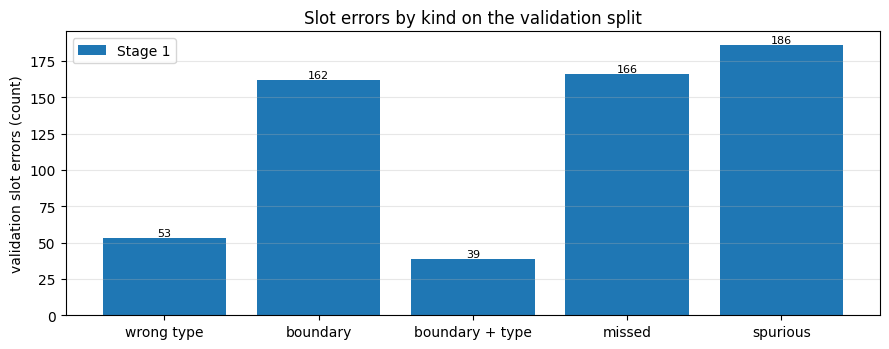

In [21]:
stage1_diag = diagnose("Stage 1", stage1_dev_int, stage1_dev_tags)
plot_error_breakdown([stage1_diag], FIG_DIR / "stage1_errors.png")

In [22]:
show_errors(stage1_dev_int, stage1_dev_tags, n=25)

687 of 2,033 validation utterances have at least one error; a fixed random sample of 25:

- what can i cook with broccoli and chicken
    intent  gold cooking_recipe           pred cooking_recipe
    slots   gold [ingredient : broccoli] [ingredient : chicken]
            pred [food_type : broccoli and chicken]
- read back what i put on my to do list for this week
    intent  gold lists_query              pred lists_query
    slots   gold [date : this week]
            pred [date : this week] [list_name : to do]
- never ever play me any country
    intent  gold music_dislikeness        pred play_game   <- intent wrong
    slots   gold [music_genre : country]
            pred [music_genre : country]
- remind to at eight p. m. to take my medicine
    intent  gold calendar_set             pred calendar_set
    slots   gold [event_name : medicine] [time : eight p. m.]
            pred [event_name : take my medicine] [time : eight p. m.]
- request a taxi from udrive service
    intent  gold 

## 15. From diagnosis to Stage 2 changes

Each candidate change answers a weakness measured in Section 14 (see its output for the numbers). They are tried in this order, strongest evidence first:

| Order | Change                                    | Weakness it targets (Section 14)                                                                               |
| ----- | ----------------------------------------- | -------------------------------------------------------------------------------------------------------------- |
| 1     | **Character CNN** word features           | Utterances and gold spans containing a word outside the training vocabulary score far lower than the rest      |
| 2     | **CRF** slot decoder with BIO constraints | Boundary errors, invalid `I-` tags, gold spans split into pieces, more predicted than gold spans               |
| 3     | **Attention pooling** for the intent      | Intent errors, mostly across scenarios                                                                         |
| 4     | **Intent-to-slot gate**                   | Slot types never seen with the predicted intent; wrong-type errors. These are few, so a small gain is expected |
| 5     | **Learning-rate decay** on plateau        | Validation loss rises after the first epochs while the scores still improve                                    |

**Protocol (validation only).** Greedy forward selection: each change is added to the current best configuration and trained with the same 3 seeds as Section 12. It is kept only if the mean validation selection score improves by more than a noise margin of 2 x sqrt(2/3) x (Stage 1 seed standard deviation), which is twice the standard error of a difference between two 3-seed means. Then every kept change is removed again (leave-one-out), and two extra ablations probe the embeddings and the slot-loss weight. The test split is used once, at the end.

All Stage 2 models reuse the Stage 1 training loop, data, vocabulary and evaluation functions unchanged.


In [ ]:
import math
import torch.nn.functional as F

STAGE2_BASE = {**STAGE1_CFG,
               "char_cnn": False, "crf": False, "intent_pool": "max", "slot_gate": False,
               "lr_schedule": "none", "slot_loss_weight": 1.0, "emb_init": "glove", "freeze_emb": False}
STAGE2_STEPS = [
    ("+ character CNN", {"char_cnn": True}),
    ("+ CRF", {"crf": True}),
    ("+ attention pooling", {"intent_pool": "attention"}),
    ("+ intent-to-slot gate", {"slot_gate": True}),
    ("+ LR decay on plateau", {"lr_schedule": "plateau"}),
]
STAGE2_SEEDS = [OFFICIAL_SEED] + EXTRA_SEEDS
STAGE1_SCORE_STD = stage1_seeds_df["dev_score"].std(ddof=1)
KEEP_MARGIN = 2 * math.sqrt(2 / len(STAGE2_SEEDS)) * STAGE1_SCORE_STD
RUN_EXTRA_ABLATIONS = True   # embeddings + slot-loss weight; set False to save about 45 minutes
print(f"Stage 1 seed std of the selection score: {STAGE1_SCORE_STD:.3f} -> keep margin {KEEP_MARGIN:.3f}")

MAX_WORD_LEN = 20
CHAR_ITOS = ["<pad>", "<unk>"] + sorted({ch for ex in EXAMPLES["train"] for w in ex["words"] for ch in w})
CHAR2ID = {c: i for i, c in enumerate(CHAR_ITOS)}
N_CHARS = len(CHAR_ITOS)
for name, data in DATASETS.items():
    for i, enc in data:
        enc["char_ids"] = [[CHAR2ID.get(ch, 1) for ch in w[:MAX_WORD_LEN]] for w in EXAMPLES[name][i]["words"]]
print(f"character vocabulary: {N_CHARS} symbols (including <pad>, <unk>)")


def collate_with_chars(batch):
    """Same as the Stage 1 collate, plus a (batch, tokens, characters) tensor of character ids."""
    out = collate_stage1(batch)
    items = [b[1] for b in batch]
    L = max(len(c) for x in items for c in x["char_ids"])
    chars = torch.zeros((len(items), out["ids"].size(1), L), dtype=torch.long)
    for i, x in enumerate(items):
        for t, c in enumerate(x["char_ids"]):
            chars[i, t, :len(c)] = torch.tensor(c)
    out["chars"] = chars
    return out


if "collate_stage1" not in globals():   # guard so that re-running this cell is safe
    collate_stage1 = collate
collate = collate_with_chars   # used by make_loader from here on; Stage 1 models simply ignore "chars"

# Input-only statistic (no labels): how many validation words outside the training vocabulary does GloVe know?
_oov = [w for ex in EXAMPLES["dev"] for w in ex["words"] if w not in STOI]
print(f"validation tokens outside the training vocabulary: {len(_oov):,}; of these, in GloVe 6B: {100 * sum(w in GLOVE_WORDS for w in _oov) / max(len(_oov), 1):.1f}%")

Stage 1 seed std of the selection score: 0.210 -> keep margin 0.343
character vocabulary: 34 symbols (including <pad>, <unk>)
validation tokens outside the training vocabulary: 449; of these, in GloVe 6B: 93.3%


In [ ]:
class CRF(nn.Module):
    """Linear-chain conditional random field over tag sequences.
    allowed[i, j] = 1 if tag j may follow tag i; start_allowed[j] = 1 if tag j may start a sequence.
    Forbidden moves get a -1e4 score in both training and decoding, so they are never predicted."""

    def __init__(self, n_tags, allowed=None, start_allowed=None):
        super().__init__()
        self.n_tags = n_tags
        self.transitions = nn.Parameter(torch.empty(n_tags, n_tags).uniform_(-0.1, 0.1))
        self.start = nn.Parameter(torch.empty(n_tags).uniform_(-0.1, 0.1))
        self.end = nn.Parameter(torch.empty(n_tags).uniform_(-0.1, 0.1))
        allowed = torch.ones(n_tags, n_tags) if allowed is None else allowed.float()
        start_allowed = torch.ones(n_tags) if start_allowed is None else start_allowed.float()
        self.register_buffer("trans_penalty", (1 - allowed) * -1e4)
        self.register_buffer("start_penalty", (1 - start_allowed) * -1e4)

    def nll(self, emissions, tags, mask):
        """Negative log-likelihood of the gold tags, averaged over real tokens (same scale as token cross-entropy)."""
        B, T, K = emissions.shape
        tags = torch.where(mask & (tags >= 0), tags, torch.zeros_like(tags))
        oh = F.one_hot(tags, K).to(emissions.dtype)          # one-hot instead of gather: deterministic on GPU
        maskf = mask.to(emissions.dtype)
        trans, start = self.transitions + self.trans_penalty, self.start + self.start_penalty
        gold = ((emissions * oh).sum(-1) * maskf).sum(1) + (oh[:, 0] * start).sum(-1)
        gold = gold + (torch.einsum("btk,kl,btl->bt", oh[:, :-1], trans, oh[:, 1:]) * maskf[:, 1:]).sum(1)
        last = mask.sum(1) - 1
        gold = gold + (oh[torch.arange(B, device=tags.device), last] * self.end).sum(-1)
        alpha = start + emissions[:, 0]
        for t in range(1, T):
            nxt = torch.logsumexp(alpha.unsqueeze(2) + trans.unsqueeze(0), dim=1) + emissions[:, t]
            alpha = torch.where(mask[:, t].unsqueeze(1), nxt, alpha)
        log_z = torch.logsumexp(alpha + self.end, dim=1)
        return (log_z - gold).sum() / maskf.sum()

    @torch.no_grad()
    def viterbi(self, emissions, mask):
        """Highest-scoring tag sequence for each sentence, shape (batch, tokens)."""
        B, T, K = emissions.shape
        trans = self.transitions + self.trans_penalty
        score = self.start + self.start_penalty + emissions[:, 0]
        same = torch.arange(K, device=emissions.device).expand(B, K)
        backpointers = []
        for t in range(1, T):
            best, idx = (score.unsqueeze(2) + trans.unsqueeze(0)).max(dim=1)
            m = mask[:, t].unsqueeze(1)
            score = torch.where(m, best + emissions[:, t], score)
            backpointers.append(torch.where(m, idx, same))
        last = (score + self.end).argmax(1)
        path = [last]
        for idx in reversed(backpointers):
            last = idx.gather(1, last.unsqueeze(1)).squeeze(1)
            path.append(last)
        return torch.stack(path[::-1], dim=1)


def bio_constraints(tag_names):
    """I-X may only follow B-X or I-X, and may not start a sentence."""
    K = len(tag_names)
    allowed, start = torch.zeros(K, K), torch.zeros(K)
    for j, tj in enumerate(tag_names):
        start[j] = not tj.startswith("I-")
        for i, ti in enumerate(tag_names):
            allowed[i, j] = (not tj.startswith("I-")) or (ti != "O" and ti[2:] == tj[2:])
    return allowed, start


# Unit tests: compare with brute-force enumeration of every tag sequence
import itertools

def _brute(crf, em, length, gold=None):
    trans = crf.transitions + crf.trans_penalty
    start = crf.start + crf.start_penalty
    scores = {}
    for path in itertools.product(range(crf.n_tags), repeat=length):
        s = start[path[0]] + em[0, path[0]] + crf.end[path[-1]]
        for t in range(1, length):
            s = s + trans[path[t - 1], path[t]] + em[t, path[t]]
        scores[path] = s
    log_z = torch.logsumexp(torch.stack(list(scores.values())), 0)
    best = max(scores, key=lambda p: scores[p].item())
    nll = (log_z - scores[tuple(gold)]).item() if gold is not None else None
    return best, nll

torch.manual_seed(0)
_names = ["O", "B-a", "I-a", "B-b", "I-b"]
for constrained in (False, True):
    _crf = CRF(5, *bio_constraints(_names)) if constrained else CRF(5)
    _em = torch.randn(2, 4, 5)
    _mask = torch.tensor([[1, 1, 1, 1], [1, 1, 1, 0]], dtype=torch.bool)
    _gold = torch.tensor([[1, 2, 0, 3], [3, 4, 0, -100]])
    _vit = _crf.viterbi(_em, _mask)
    total = 0.0
    for b, n in enumerate([4, 3]):
        best, nll = _brute(_crf, _em[b], n, _gold[b, :n].tolist())
        assert tuple(_vit[b, :n].tolist()) == best, (constrained, b)
        total += nll
    assert abs(_crf.nll(_em, _gold, _mask).item() - total / 7) < 1e-4
    if constrained:
        _many = _crf.viterbi(torch.randn(64, 6, 5) * 3, torch.ones(64, 6, dtype=torch.bool))
        assert invalid_bio([[_names[k] for k in row] for row in _many.tolist()]) == (0, 0)
print("CRF unit tests passed (forward algorithm and Viterbi match brute force; constrained decoding never emits invalid BIO)")

CRF unit tests passed (forward algorithm and Viterbi match brute force; constrained decoding never emits invalid BIO)


## 16. Stage 2 model: one configurable joint model

Every candidate is a switch on the same model, so each comparison changes exactly one thing. With every switch off, it is the Stage 1 architecture.

| Part                 | Off (Stage 1)                     | On (Stage 2 option)                                                                                                                             |
| -------------------- | --------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------- |
| Word input           | GloVe embedding (V x 300)         | + **character CNN**: 50-d character embeddings, 100 filters of width 3, max-pooled over the word, concatenated to the word vector (400-d input) |
| Encoder              | 2-layer BiLSTM, 256 per direction | unchanged                                                                                                                                       |
| Sentence vector      | max-pool over real tokens         | **attention pooling**: a learned score per token, softmax over real tokens, weighted sum                                                        |
| Slot input per token | BiLSTM output h_i (512)           | **intent-to-slot gate**: g_i = sigmoid(W [h_i ; c]), input [h_i ; g_i * c] (1024), with c the sentence vector                                   |
| Slot decoder         | softmax per token, cross-entropy  | **CRF** with BIO constraints: transition scores between tags, trained with the sequence log-likelihood (per token), decoded with Viterbi        |
| Learning rate        | constant                          | **halved** after 3 epochs without a better validation score                                                                                     |

The loss is CE(intent) + lambda x slot loss, with lambda = 1 unless stated. Everything else (optimizer, dropout, word dropout, early stopping, selection score) is the Stage 1 recipe from Section 9.


In [ ]:
class CharCNN(nn.Module):
    def __init__(self, n_chars, dim=50, filters=100, kernel=3, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(n_chars, dim, padding_idx=0)
        self.dropout = nn.Dropout(dropout)
        self.conv = nn.Conv1d(dim, filters, kernel, padding=kernel // 2)
        self.out_dim = filters

    def forward(self, chars):                       # (B, T, L) character ids
        B, T, L = chars.shape
        flat = chars.reshape(B * T, L)
        x = self.conv(self.dropout(self.emb(flat)).transpose(1, 2))
        x = x.masked_fill((flat == 0).unsqueeze(1), float("-inf"))
        return torch.relu(x.max(dim=2).values).reshape(B, T, -1)   # padding words give all -inf -> 0


EMB_MATRIX_RANDOM = np.random.default_rng(1).normal(0.0, EMB_MATRIX[2:].std(), size=EMB_MATRIX.shape).astype(np.float32)
EMB_MATRIX_RANDOM[PAD] = 0.0


class JointModelV2(nn.Module):
    """Stage 2: the Stage 1 joint BiLSTM plus optional character CNN, attention pooling, intent-to-slot gate and CRF."""

    def __init__(self, n_chars, n_intents, n_tags, hidden=256, layers=2, dropout=0.3, word_dropout=0.1,
                 char_cnn=False, crf=False, intent_pool="max", slot_gate=False, slot_loss_weight=1.0,
                 emb_init="glove", freeze_emb=False, **_unused):
        super().__init__()
        self.word_dropout, self.intent_pool, self.slot_loss_weight = word_dropout, intent_pool, slot_loss_weight
        matrix = EMB_MATRIX if emb_init == "glove" else EMB_MATRIX_RANDOM
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(matrix), freeze=freeze_emb, padding_idx=PAD)
        self.char_cnn = CharCNN(n_chars, dropout=dropout) if char_cnn else None
        in_dim = matrix.shape[1] + (self.char_cnn.out_dim if char_cnn else 0)
        self.emb_dropout = nn.Dropout(dropout)
        self.encoder = nn.LSTM(in_dim, hidden, num_layers=layers, bidirectional=True, batch_first=True,
                               dropout=dropout if layers > 1 else 0.0)
        self.head_dropout = nn.Dropout(dropout)
        self.intent_att = nn.Linear(2 * hidden, 1) if intent_pool == "attention" else None
        self.intent_head = nn.Linear(2 * hidden, n_intents)
        self.gate = nn.Linear(4 * hidden, 2 * hidden) if slot_gate else None
        self.slot_head = nn.Linear(4 * hidden if slot_gate else 2 * hidden, n_tags)
        self.crf = CRF(n_tags, *bio_constraints(ID2TAG)) if crf else None
        self.ce = nn.CrossEntropyLoss(ignore_index=IGNORE)

    def forward(self, batch):
        ids, lengths, mask = batch["ids"], batch["lengths"], batch["mask"]
        if self.training and self.word_dropout > 0:
            drop = (torch.rand(ids.shape, device=ids.device) < self.word_dropout) & mask
            ids = ids.masked_fill(drop, UNK)
        x = self.embedding(ids)
        if self.char_cnn is not None:
            x = torch.cat([x, self.char_cnn(batch["chars"])], dim=-1)
        x = self.emb_dropout(x)
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.encoder(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=ids.size(1))
        if self.intent_att is not None:
            a = self.intent_att(h).squeeze(-1).masked_fill(~mask, float("-inf"))
            sent = (torch.softmax(a, dim=1).unsqueeze(-1) * h).sum(1)
        else:
            sent = h.masked_fill(~mask.unsqueeze(-1), float("-inf")).max(dim=1).values
        tok = h
        if self.gate is not None:
            c = sent.unsqueeze(1).expand_as(h)
            tok = torch.cat([h, torch.sigmoid(self.gate(torch.cat([h, c], dim=-1))) * c], dim=-1)
        return {"intent": self.intent_head(self.head_dropout(sent)), "slot": self.slot_head(self.head_dropout(tok))}

    def loss(self, out, batch):
        intent_loss = self.ce(out["intent"], batch["intents"])
        if self.crf is not None:
            slot_loss = self.crf.nll(out["slot"], batch["tags"], batch["mask"])
        else:
            slot_loss = self.ce(out["slot"].reshape(-1, out["slot"].size(-1)), batch["tags"].reshape(-1))
        return {"total": intent_loss + self.slot_loss_weight * slot_loss, "intent": intent_loss, "slot": slot_loss}

    def decode(self, out, batch):
        intents = out["intent"].argmax(-1).tolist()
        tags = (self.crf.viterbi(out["slot"], batch["mask"]) if self.crf is not None else out["slot"].argmax(-1)).tolist()
        return intents, [t[:n] for t, n in zip(tags, batch["lengths"].tolist())]


def build_stage2(cfg):
    return JointModelV2(N_CHARS, N_INTENTS, N_TAGS, **cfg)


_all_on = {**STAGE2_BASE, **{k: v for _, change in STAGE2_STEPS for k, v in change.items()}}
_df, _total, _ = param_breakdown(build_stage2(_all_on))
display(_df)
print(f"Stage 2 with every option on: {_total:,} parameters (cap {PARAM_CAP:,})")
assert _total <= PARAM_CAP

,component,parameters
0,embedding,"1,543,500"
1,char_cnn,"16,800"
2,encoder,"2,924,544"
3,intent_att,513
4,intent_head,"30,780"
5,gate,"524,800"
6,slot_head,"113,775"
7,crf,"12,543"
8,TOTAL,"5,167,255"
9,trainable,"5,167,255"


Stage 2 with every option on: 5,167,255 parameters (cap 20,000,000)


## 17. Stage 2 development: greedy forward selection (validation only)

The first row is Stage 1 itself (its 3 seeds from Section 12). Each later row adds one change to the best configuration so far and trains the same 3 seeds. "kept" means the mean validation selection score improved by more than the keep margin printed in Section 15. Results are cached in memory, so a configuration that appears twice below is trained only once in this run.


In [26]:
EXPERIMENTS = {}   # (configuration, seed) -> best validation row, filled only by runs in this notebook


def run_seeds(name, cfg, seeds=STAGE2_SEEDS):
    rows = []
    for s in seeds:
        key = (tuple(sorted(cfg.items())), s)
        if key not in EXPERIMENTS:
            t0 = time.time()
            m, hist, best = run_training(build_stage2, cfg, seed=s, verbose=False, stage="stage2-dev")
            del m
            EXPERIMENTS[key] = dict(best, epochs_run=len(hist), minutes=(time.time() - t0) / 60)
        rows.append(EXPERIMENTS[key])
    d = pd.DataFrame(rows)
    res = dict(experiment=name,
               intent_mean=d["dev_intent_acc"].mean(), intent_std=d["dev_intent_acc"].std(ddof=1),
               slot_f1_mean=d["dev_slot_f1"].mean(), slot_f1_std=d["dev_slot_f1"].std(ddof=1),
               score_mean=d["dev_score"].mean(), score_std=d["dev_score"].std(ddof=1),
               best_epochs=" / ".join(str(int(e)) for e in d["epoch"]), minutes=d["minutes"].sum())
    print(f"{name:34s} intent {res['intent_mean']:.2f} +/- {res['intent_std']:.2f} | slot F1 {res['slot_f1_mean']:.2f} +/- "
          f"{res['slot_f1_std']:.2f} | score {res['score_mean']:.2f} +/- {res['score_std']:.2f} | {res['minutes']:.1f} min")
    return res


stage1_row = dict(experiment="Stage 1 (Section 12)",
                  intent_mean=stage1_seeds_df["dev_intent_acc"].mean(), intent_std=stage1_seeds_df["dev_intent_acc"].std(ddof=1),
                  slot_f1_mean=stage1_seeds_df["dev_slot_f1"].mean(), slot_f1_std=stage1_seeds_df["dev_slot_f1"].std(ddof=1),
                  score_mean=stage1_seeds_df["dev_score"].mean(), score_std=stage1_seeds_df["dev_score"].std(ddof=1),
                  best_epochs=" / ".join(str(int(e)) for e in stage1_seeds_df["best_epoch"]), minutes=float("nan"),
                  gain=float("nan"), kept="baseline")

current_cfg, current = dict(STAGE2_BASE), stage1_row
dev_rows, KEPT = [stage1_row], []
for name, change in STAGE2_STEPS:
    cand = {**current_cfg, **change}
    r = run_seeds(name, cand)
    r["gain"] = r["score_mean"] - current["score_mean"]
    r["kept"] = "yes" if r["gain"] > KEEP_MARGIN else "no"
    dev_rows.append(r)
    if r["kept"] == "yes":
        current_cfg, current = cand, r
        KEPT.append((name, change))

STAGE2_CFG = current_cfg
stage2_dev_df = pd.DataFrame(dev_rows)
display(stage2_dev_df.round(2))
stage2_dev_df.to_csv("stage2_development.csv", index=False)
print(f"kept: {[n for n, _ in KEPT]}")
print("Stage 2 configuration:", {k: v for k, v in STAGE2_CFG.items() if STAGE2_BASE.get(k) != v} or "(no change kept)")

+ character CNN                    intent 86.95 +/- 0.54 | slot F1 78.42 +/- 0.19 | score 82.69 +/- 0.35 | 12.9 min
+ CRF                              intent 87.01 +/- 0.23 | slot F1 80.80 +/- 0.53 | score 83.91 +/- 0.37 | 15.1 min
+ attention pooling                intent 87.00 +/- 0.23 | slot F1 81.33 +/- 0.38 | score 84.17 +/- 0.10 | 17.2 min
+ intent-to-slot gate              intent 86.98 +/- 0.22 | slot F1 80.17 +/- 0.59 | score 83.58 +/- 0.31 | 14.4 min
+ LR decay on plateau              intent 87.08 +/- 0.24 | slot F1 81.68 +/- 0.49 | score 84.38 +/- 0.31 | 20.4 min


,experiment,intent_mean,intent_std,slot_f1_mean,slot_f1_std,score_mean,score_std,best_epochs,minutes,gain,kept
0,Stage 1 (Section 12),86.60,0.59,77.47,0.51,82.04,0.21,23 / 20 / 27,NaN,NaN,baseline
1,+ character CNN,86.95,0.54,78.42,0.19,82.69,0.35,28 / 31 / 41,12.91,0.65,yes
2,+ CRF,87.01,0.23,80.80,0.53,83.91,0.37,23 / 35 / 17,15.15,1.22,yes
3,+ attention pooling,87.00,0.23,81.33,0.38,84.17,0.10,26 / 34 / 27,17.22,0.26,no
4,+ intent-to-slot gate,86.98,0.22,80.17,0.59,83.58,0.31,25 / 32 / 10,14.36,-0.33,no
5,+ LR decay on plateau,87.08,0.24,81.68,0.49,84.38,0.31,35 / 31 / 44,20.43,0.48,yes


kept: ['+ character CNN', '+ CRF', '+ LR decay on plateau']
Stage 2 configuration: {'char_cnn': True, 'crf': True, 'lr_schedule': 'plateau'}


## 18. Ablations (validation only)

**Leave-one-out:** each kept change is removed from the final configuration, to check that it still matters in the presence of the others. **Extra ablations** (if `RUN_EXTRA_ABLATIONS`): frozen GloVe embeddings, randomly initialised embeddings (what GloVe contributes), and the slot-loss weight lambda at 0.5 and 2.


In [27]:
final_row = dev_rows[[r["experiment"] for r in dev_rows].index(KEPT[-1][0])] if KEPT else stage1_row
abl_rows = [dict(final_row, experiment="Final Stage 2 configuration", change=float("nan"))]
for name, change in KEPT:
    cfg = {**STAGE2_CFG, **{k: STAGE2_BASE[k] for k in change}}
    r = run_seeds(f"without {name[2:]}", cfg)
    r["change"] = r["score_mean"] - final_row["score_mean"]
    abl_rows.append(r)

if RUN_EXTRA_ABLATIONS:
    for name, change in [("frozen GloVe embeddings", {"freeze_emb": True}),
                         ("random embeddings (no GloVe)", {"emb_init": "random"}),
                         ("slot-loss weight lambda = 0.5", {"slot_loss_weight": 0.5}),
                         ("slot-loss weight lambda = 2", {"slot_loss_weight": 2.0})]:
        r = run_seeds(name, {**STAGE2_CFG, **change})
        r["change"] = r["score_mean"] - final_row["score_mean"]
        abl_rows.append(r)

stage2_ablation_df = pd.DataFrame(abl_rows)
display(stage2_ablation_df.drop(columns=["gain", "kept"], errors="ignore").round(2))
stage2_ablation_df.to_csv("stage2_ablations.csv", index=False)

without character CNN              intent 87.11 +/- 0.21 | slot F1 81.41 +/- 0.27 | score 84.26 +/- 0.24 | 20.5 min
without CRF                        intent 87.23 +/- 0.50 | slot F1 78.85 +/- 0.63 | score 83.04 +/- 0.25 | 14.0 min
without LR decay on plateau        intent 87.01 +/- 0.23 | slot F1 80.80 +/- 0.53 | score 83.91 +/- 0.37 | 15.1 min
frozen GloVe embeddings            intent 87.16 +/- 0.60 | slot F1 81.32 +/- 0.39 | score 84.24 +/- 0.10 | 19.2 min
random embeddings (no GloVe)       intent 86.83 +/- 0.19 | slot F1 80.76 +/- 0.07 | score 83.80 +/- 0.12 | 23.4 min
slot-loss weight lambda = 0.5      intent 87.36 +/- 0.34 | slot F1 81.02 +/- 0.29 | score 84.19 +/- 0.28 | 19.3 min
slot-loss weight lambda = 2        intent 87.13 +/- 0.36 | slot F1 81.86 +/- 0.19 | score 84.49 +/- 0.26 | 14.3 min


,experiment,intent_mean,intent_std,slot_f1_mean,slot_f1_std,score_mean,score_std,best_epochs,minutes,change
0,Final Stage 2 configuration,87.08,0.24,81.68,0.49,84.38,0.31,35 / 31 / 44,20.43,NaN
1,without character CNN,87.11,0.21,81.41,0.27,84.26,0.24,49 / 32 / 43,20.54,-0.12
2,without CRF,87.23,0.50,78.85,0.63,83.04,0.25,40 / 33 / 37,13.99,-1.34
3,without LR decay on plateau,87.01,0.23,80.80,0.53,83.91,0.37,23 / 35 / 17,15.15,-0.48
4,frozen GloVe embeddings,87.16,0.60,81.32,0.39,84.24,0.10,29 / 39 / 34,19.20,-0.14
5,random embeddings (no GloVe),86.83,0.19,80.76,0.07,83.80,0.12,49 / 43 / 50,23.36,-0.58
6,slot-loss weight lambda = 0.5,87.36,0.34,81.02,0.29,84.19,0.28,44 / 27 / 31,19.30,-0.19
7,slot-loss weight lambda = 2,87.13,0.36,81.86,0.19,84.49,0.26,23 / 24 / 21,14.34,0.11


## 19. Stage 2 official training run and checkpoint selection

The selected Stage 2 configuration, trained with the same fixed seed as Stage 1. Same logging and checkpoint rule as Section 10.


In [28]:
_df, _total, _trainable = param_breakdown(build_stage2(STAGE2_CFG))
display(_df)
print(f"total parameters in the Stage 2 pipeline: {_total:,} (cap {PARAM_CAP:,})")
assert _total <= PARAM_CAP

STAGE2_CKPT = CKPT_DIR / "stage2_best.pt"
stage2_train_model, stage2_history, stage2_best = run_training(
    build_stage2, STAGE2_CFG, seed=OFFICIAL_SEED, ckpt_path=STAGE2_CKPT, verbose=True, stage="stage2")
del stage2_train_model
pd.DataFrame(stage2_history).to_csv("stage2_history.csv", index=False)

print(f"\nselected checkpoint: epoch {stage2_best['epoch']} (of {len(stage2_history)} run)")
print(f"validation selection score: {stage2_best['dev_score']:.2f} "
      f"(intent accuracy {stage2_best['dev_intent_acc']:.2f}, slot micro F1 {stage2_best['dev_slot_f1']:.2f})")
print(f"checkpoint file: {STAGE2_CKPT}")
print(f"total training time: {stage2_history[-1]['elapsed_seconds'] / 60:.1f} min")

,component,parameters
0,embedding,"1,543,500"
1,char_cnn,"16,800"
2,encoder,"2,924,544"
3,intent_head,"30,780"
4,slot_head,"56,943"
5,crf,"12,543"
6,TOTAL,"4,585,110"
7,trainable,"4,585,110"


total parameters in the Stage 2 pipeline: 4,585,110 (cap 20,000,000)
epoch | train loss | dev loss | dev intent | dev slot F1 | dev score |   time
    1 |     3.4583 |   1.6256 |      66.90 |       39.83 |     53.36 |   9.4s *
    2 |     1.4276 |   1.0123 |      80.47 |       62.73 |     71.60 |   9.4s *
    3 |     1.0166 |   0.8455 |      84.06 |       68.94 |     76.50 |   9.4s *
    4 |     0.7998 |   0.7834 |      84.46 |       73.78 |     79.12 |   9.4s *
    5 |     0.6618 |   0.7410 |      85.19 |       75.07 |     80.13 |   9.3s *
    6 |     0.5672 |   0.7404 |      85.15 |       75.63 |     80.39 |   9.4s *
    7 |     0.5015 |   0.7600 |      85.98 |       76.65 |     81.32 |   9.4s *
    8 |     0.4460 |   0.7553 |      85.54 |       77.25 |     81.39 |   9.4s *
    9 |     0.3982 |   0.7544 |      85.88 |       77.74 |     81.81 |   9.4s *
   10 |     0.3600 |   0.7373 |      86.67 |       78.73 |     82.70 |   9.4s *
   11 |     0.3383 |   0.7593 |      86.03 |       78

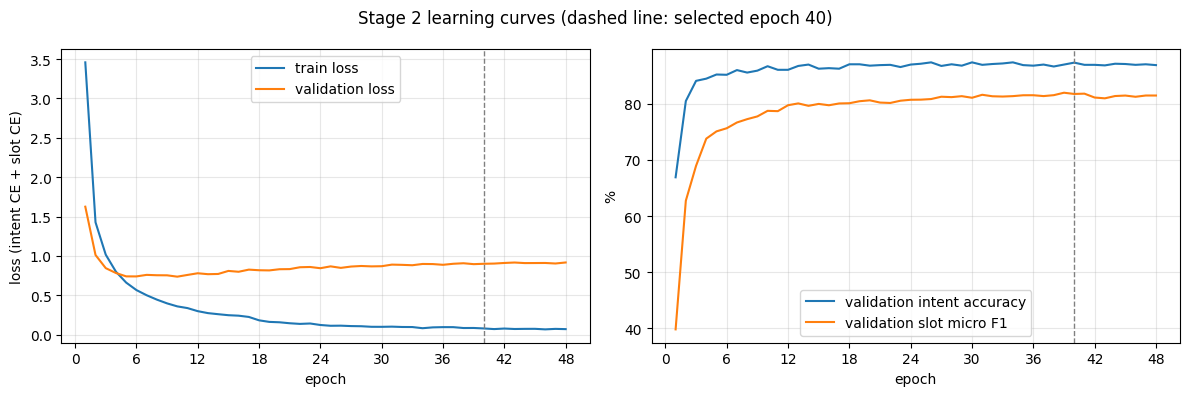

In [29]:
plot_curves(stage2_history, stage2_best["epoch"], "Stage 2 learning curves", FIG_DIR / "stage2_curves.png")

## 20. Stage 2 final evaluation from the saved checkpoint

Fresh model, checkpoint loaded from disk, no further training. The validation score must equal the logged best; then the test split is evaluated once.


In [30]:
stage2_model, stage2_ck = load_checkpoint(STAGE2_CKPT, build_stage2)
stage2_dev, stage2_dev_int, stage2_dev_tags = evaluate(stage2_model, "dev")
stage2_test, _, stage2_test_tags = evaluate(stage2_model, "test")

print(f"checkpoint: {STAGE2_CKPT} (epoch {stage2_ck['epoch']})")
print(f"validation score logged during training: {stage2_ck['dev_metrics']['dev_score']:.6f}")
print(f"validation score after reloading:       {stage2_dev['score']:.6f}")
assert abs(stage2_dev["score"] - stage2_ck["dev_metrics"]["dev_score"]) < 1e-6

_seqeval_f1 = 100 * seqeval.metrics.f1_score([ex["tags"] for ex in EXAMPLES["dev"]], stage2_dev_tags)
print(f"validation slot F1: ours {stage2_dev['slot_f1']:.2f}, seqeval {_seqeval_f1:.2f}")
if STAGE2_CFG["crf"]:
    assert invalid_bio(stage2_dev_tags) == (0, 0) and invalid_bio(stage2_test_tags) == (0, 0)
    print("constrained CRF: no invalid BIO sequences on validation or test")

_cols = ("intent_acc", "slot_f1", "slot_precision", "slot_recall", "exact_match")
stage2_eval_df = pd.DataFrame([
    {"split": "validation", **{k: stage2_dev[k] for k in _cols}},
    {"split": "test", **{k: stage2_test[k] for k in _cols}},
])
display(stage2_eval_df.round(2))
print(f"\nStage 2 TEST: intent accuracy {stage2_test['intent_acc']:.2f}%, slot micro F1 {stage2_test['slot_f1']:.2f}%")

checkpoint: checkpoints/stage2_best.pt (epoch 40)
validation score logged during training: 84.520800
validation score after reloading:       84.520800
validation slot F1: ours 81.73, seqeval 81.73
constrained CRF: no invalid BIO sequences on validation or test


,split,intent_acc,slot_f1,slot_precision,slot_recall,exact_match
0,validation,87.31,81.73,81.85,81.61,70.09
1,test,86.85,79.49,80.24,78.76,68.36



Stage 2 TEST: intent accuracy 86.85%, slot micro F1 79.49%


## 21. Stage 2 diagnosis and comparison with Stage 1 (validation only)

The Section 14 analyses again, on the Stage 2 validation predictions, with the error breakdown of both systems side by side.


=== Stage 2: diagnosis on dev (2,033 utterances) ===


,measure,value
0,intent accuracy / slot F1 / exact match,87.31 / 81.73 / 70.09
1,slot precision / recall,81.85 / 81.61
2,predicted slot spans / gold slot spans,"2,006 / 2,012"
3,slot errors (all kinds),523
4,invalid I- tags (utterances affected),0 (0)
5,gold spans split into several predicted pieces,15
6,"utterances with an OOV word: n, intent acc, slot F1","351, 74.93, 68.93"
7,"utterances without OOV words: n, intent acc, slot F1","1,682, 89.89, 84.61"
8,gold spans with / without an OOV word: exact recall,"57.75 (n=213) / 84.44 (n=1,799)"
9,predicted spans with a type never seen with the predicted intent (share wrong),"27 of 2,006 (63.0% wrong)"


,kind,count,share_of_errors
0,wrong type,60,11.5
1,boundary,108,20.7
2,boundary + type,49,9.4
3,missed,153,29.3
4,spurious,153,29.3


most confused intent pairs (gold -> predicted):


,gold -> predicted,count
0,"(general_quirky, news_query)",9
1,"(qa_factoid, general_quirky)",6
2,"(general_quirky, cooking_recipe)",5
3,"(calendar_set, calendar_query)",5
4,"(play_music, play_radio)",4
5,"(qa_factoid, qa_definition)",4
6,"(general_quirky, qa_definition)",4
7,"(general_quirky, weather_query)",4
8,"(recommendation_events, news_query)",4
9,"(general_quirky, qa_factoid)",4


weakest slot types (at least 10 gold spans in validation):


,slot_type,train_count,dev_gold,tp,fp,fn,f1
33,news_topic,183,40,19,20,21,48.10
42,radio_name,131,21,11,13,10,48.89
40,podcast_descriptor,68,10,5,5,5,50.00
4,audiobook_name,73,16,8,7,8,51.61
44,song_name,128,23,11,7,12,53.66
22,general_frequency,84,15,8,6,7,55.17
38,player_setting,160,36,24,13,12,65.75
19,food_type,295,51,38,21,13,69.09
2,artist_name,232,45,30,9,15,71.43
27,meal_type,63,12,11,7,1,73.33


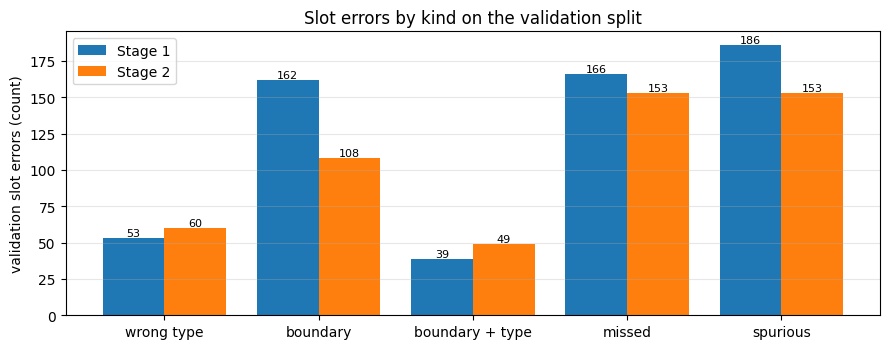

,measure,Stage 1,Stage 2
0,intent accuracy / slot F1 / exact match,87.01 / 77.55 / 66.21,87.31 / 81.73 / 70.09
1,slot precision / recall,76.03 / 79.13,81.85 / 81.61
2,predicted slot spans / gold slot spans,"2,094 / 2,012","2,006 / 2,012"
3,slot errors (all kinds),606,523
4,invalid I- tags (utterances affected),98 (90),0 (0)
5,gold spans split into several predicted pieces,67,15
6,"utterances with an OOV word: n, intent acc, slot F1","351, 74.93, 61.17","351, 74.93, 68.93"
7,"utterances without OOV words: n, intent acc, slot F1","1,682, 89.54, 81.22","1,682, 89.89, 84.61"
8,gold spans with / without an OOV word: exact recall,"42.72 (n=213) / 83.44 (n=1,799)","57.75 (n=213) / 84.44 (n=1,799)"
9,predicted spans with a type never seen with the predicted intent (share wrong),"44 of 2,094 (75.0% wrong)","27 of 2,006 (63.0% wrong)"


In [31]:
stage2_diag = diagnose("Stage 2", stage2_dev_int, stage2_dev_tags)
plot_error_breakdown([stage1_diag, stage2_diag], FIG_DIR / "errors_stage1_vs_stage2.png")
compare = pd.DataFrame({
    "measure": [m for m, _ in stage1_diag["summary"]],
    "Stage 1": [v for _, v in stage1_diag["summary"]],
    "Stage 2": [v for _, v in stage2_diag["summary"]],
})
display(compare)

## 22. Final results table (Stage 1 and Stage 2)

Generated from the variables above, in the format required by the brief. "Number of epochs" is the epoch of each selected checkpoint.


In [32]:
FINAL_RESULTS = results_rows("Stage-1 system", stage1_model, stage1_dev, stage1_test, stage1_ck["epoch"]) + \
                results_rows("Stage-2 system", stage2_model, stage2_dev, stage2_test, stage2_ck["epoch"])
display(pd.DataFrame(FINAL_RESULTS))
print(f"Stage 1: selected epoch {stage1_ck['epoch']}, {len(stage1_history)} epochs run; "
      f"Stage 2: selected epoch {stage2_ck['epoch']}, {len(stage2_history)} epochs run (early stopping, patience {PATIENCE})")

with open("results_final.json", "w") as f:
    json.dump(dict(rows=FINAL_RESULTS, stage1=dict(dev=stage1_dev, test=stage1_test, cfg=STAGE1_CFG),
                   stage2=dict(dev=stage2_dev, test=stage2_test, cfg=STAGE2_CFG, kept=[n for n, _ in KEPT])), f, indent=2)

,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,Stage-1 system,Validation,"4,350,967","4,350,967",87.01,77.55,23
1,Stage-1 system,Test,Same as above,Same as above,85.84,75.12,Same as above
2,Stage-2 system,Validation,"4,585,110","4,585,110",87.31,81.73,40
3,Stage-2 system,Test,Same as above,Same as above,86.85,79.49,Same as above


Stage 1: selected epoch 23, 31 epochs run; Stage 2: selected epoch 40, 48 epochs run (early stopping, patience 8)


# Appendix: Experiments


## Stage 1 Baseline Model Experiments

- **Setup:** whitespace tokens (not the tokenizer of Section 5), frozen GloVe 6B 300d vectors, no character features, a per-token softmax slot head, seed 0, at most 80 epochs with early stopping (patience 10).
- **Recipes:** 6 optimisation recipes per family (learning rate × dropout, or learning rate × weight decay for the triangular CRF); 49 of the 54 runs finished. The table shows each family's best recipe by validation selection score, (intent accuracy + slot F1) / 2, with rows in that order.
- **Families:** CNN→BiGRU and CNN→attention put one width-3 convolution before a 1-layer BiGRU or 2 self-attention layers. ID-CNN uses dilated convolutions. The triangular CRF is a linear model that scores the intent and the tag sequence jointly, so it is the only row with a CRF.
- **Size:** every model has between 1.8M and 4.8M parameters.

| Family         | Best recipe                 | Val. intent | Val. slot F1 | Val. EM | Test intent | Test slot F1 | Test EM |
| -------------- | --------------------------- | ----------- | ------------ | ------- | ----------- | ------------ | ------- |
| BiGRU          | lr 0.002, dropout 0.2       | 87.06       | 78.91        | 67.14   | 86.25       | 75.58        | 65.60   |
| CNN→BiGRU      | lr 0.001, dropout 0.2       | 87.16       | 78.77        | 68.13   | 85.51       | 75.11        | 64.76   |
| Triangular CRF | lr 0.001, weight decay 1e-5 | 86.03       | 79.68        | 67.39   | 84.60       | 76.22        | 63.48   |
| BiLSTM         | lr 0.001, dropout 0.4       | 86.97       | 78.57        | 67.93   | 85.71       | 75.93        | 66.24   |
| TextCNN        | lr 0.0005, dropout 0.2      | 86.67       | 76.44        | 66.06   | 86.18       | 73.21        | 63.25   |
| CNN→attention  | lr 0.001, dropout 0.2       | 86.03       | 76.85        | 65.17   | 85.27       | 73.38        | 63.35   |
| Transformer    | lr 0.00025, dropout 0.2     | 86.42       | 75.55        | 63.99   | 86.01       | 73.44        | 63.42   |
| ID-CNN         | lr 0.0005, dropout 0.2      | 86.18       | 73.06        | 62.42   | 85.41       | 70.71        | 61.37   |


## Stage-2 system Experiments

| Configuration                 | Val. intent  | Val. slot F1 | Val. EM      | Test intent  | Test slot F1 | Test EM      |
| ----------------------------- | ------------ | ------------ | ------------ | ------------ | ------------ | ------------ |
| Intent label smoothing 0.1    | 87.64 ± 0.41 | 82.06 ± 0.18 | 70.55 ± 0.51 | 86.53 ± 0.30 | 79.52 ± 0.05 | 68.50 ± 0.41 |
| GloVe 840B                    | 87.56 ± 0.18 | 81.71 ± 0.53 | 70.19 ± 0.96 | 86.48 ± 0.30 | 79.33 ± 0.56 | 68.36 ± 0.89 |
| Frequency word dropout α 0.75 | 87.37 ± 0.14 | 81.82 ± 0.48 | 70.06 ± 0.59 | 85.82 ± 0.34 | 79.21 ± 0.09 | 68.21 ± 0.39 |
| fastText crawl                | 87.56 ± 0.49 | 81.47 ± 0.39 | 69.83 ± 0.36 | 86.55 ± 0.15 | 78.95 ± 0.32 | 68.16 ± 0.15 |
| Frequency word dropout α 0.25 | 87.24 ± 0.50 | 81.71 ± 0.38 | 69.80 ± 0.31 | 85.96 ± 0.39 | 78.78 ± 0.46 | 67.57 ± 0.44 |

- **Intent label smoothing 0.1:** applied to the intent loss only.
- **GloVe 840B, fastText crawl:** the word table is initialised from GloVe 840B 300d or fastText crawl-300d-2M in place of GloVe 6B, with the same vocabulary and size.
- **Frequency word dropout:** a training word *w* is replaced by the unknown token with probability α / (α + count(*w*)), in place of the uniform rate of 0.1.

No variant would be kept. Their validation selection scores are 84.48 to 84.85 against 84.81 for the retrained Stage-2 system, and the largest gain (+0.04) is below the keep margin of 0.45.

## Alternative Stage-2 Model: Co-Interactive Transformer (not kept)

As an alternative to the Stage-2 system, we also tried a Co-Interactive Transformer (Qin et al., 2021), which lets the intent and slot predictions inform each other explicitly. It did not outperform the Stage-2 system.

- **Model:** the Stage-2 system plus label attention, which splits each BiLSTM state into an intent stream and a slot stream, and one co-interactive layer, in which each stream cross-attends to the other. The intent comes from the max-pooled intent stream and the slots from the slot stream through the CRF.
- **Motivation:** in the Stage-2 system the two heads share only the BiLSTM states, so slot evidence (for example, that "five am" is a time) cannot inform the intent directly.
- **Recipe:** as the Stage-2 system, except learning rate 5e-4 and dropout 0.5, because at 1e-3 the attention layers did not train (slot F1 4.0 after 6 epochs). One co-interactive layer was chosen over two on validation.

| Model                      | Params    | Val. intent | Val. slot F1 | Val. EM | Test intent | Test slot F1 | Test EM |
| -------------------------- | --------- | ----------- | ------------ | ------- | ----------- | ------------ | ------- |
| Stage-2 system             | 4,585,110 | 87.31       | 81.73        | 70.09   | 86.85       | 79.49        | 68.36   |
| Co-Interactive Transformer | 7,565,462 | 87.85       | 80.87        | 68.81   | 86.28       | 77.83        | 67.05   |

In the official seed-42 runs above, the Co-Interactive Transformer adds 2.98M parameters yet is below the Stage-2 system on every metric except validation intent accuracy. Over seeds 42 to 44, its validation selection score is 84.31 ± 0.45, against 84.52 ± 0.41 for the Stage-2 architecture retrained with the same recipe. A variant that passes information only from intent to slots scored 0.33 above the full model, so the slot → intent direction that motivated it did not help on this data.